## 1. The data

Before building the Recurrent Neural Network (RNN), we need data. The actual stock market is incredibly complex, noisy, and influenced by countless external factors. Trying to debug a from-scratch neural network on real stock data is a recipe for disaster.

Instead, we will construct a simplified, predictable environment. In this environment, stock prices are discrete and follow specific temporal rules. This allows us to verify that our RNN is actually learning sequential dependencies.

### The Rules
We categorize stock prices into three scaled states: **Low (0.0)**, **Medium (0.5)**, and **High (1.0)**.

The price for "tomorrow" depends heavily on the sequence of "yesterday" and "today". The environment follows these primary transitions:
1. **The Floor:** If the price is low for two days in a row (0.0 $\rightarrow$ 0.0), then, more often than not, the price remains low on the next day.
2. **The Surge:** If yesterday's price was low and today's price is medium (0.0 $\rightarrow$ 0.5), then tomorrow's price will be even higher (1.0).
3. **The Crash:** When the price decreases from high to medium (1.0 $\rightarrow$ 0.5), then tomorrow's price will be even lower (0.0).
4. **The Ceiling:** If the price stays high for two days in a row (1.0 $\rightarrow$ 1.0), then the price will typically remain high tomorrow.

By generating sequences based on these rules, we create a dataset where the current state is not enough to predict the future; the network *must* remember the previous step to succeed.

In [1]:
import random
import matplotlib.pyplot as plt

def generate_sequence(length, initial_sequence):

    sequence = list(initial_sequence)

    for _ in range(length - 2):
        yesterday = sequence[-2]
        today = sequence[-1]

        # rule 1: the floor (0.0 -> 0.0) -> usually 0.0
        if yesterday == 0.0 and today == 0.0:
            # "More often than not" implies a high probability, but we add
            # slight randomness to break infinite loops.
            next_day = 0.0 if random.random() < 0.8 else 0.5

        # rule 2: the surge (0.0 -> 0.5) -> 1.0
        elif yesterday == 0.0 and today == 0.5:
            next_day = 1.0

        # rule 3: the crash (1.0 -> 0.5) -> 0.0
        elif yesterday == 1.0 and today == 0.5:
            next_day = 0.0

        # rule 4: the ceiling (1.0 -> 1.0) -> usually 1.0
        elif yesterday == 1.0 and today == 1.0:
            next_day = 1.0 if random.random() < 0.8 else 0.5

        # if we hit a transition not explicitly defined, we introduce a random walk to keep the data moving
        else:
            next_day = random.choice([0.0, 0.5, 1.0])

        sequence.append(next_day)

    return sequence



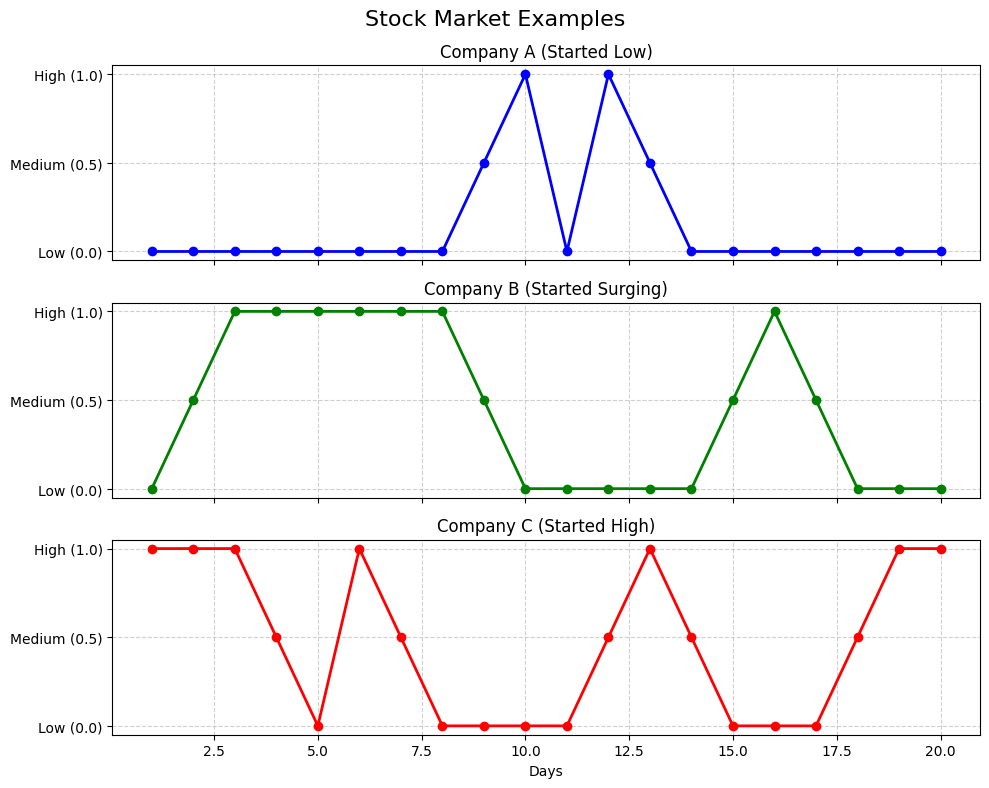

In [2]:
# generate and Plot Examples
random.seed(42)

# generate 3 distinct sequences representing different companies
seq_length = 20
company_a = generate_sequence(seq_length, [0.0, 0.0]) # starts at the Floor
company_b = generate_sequence(seq_length, [0.0, 0.5]) # starts with a Surge
company_c = generate_sequence(seq_length, [1.0, 1.0]) # starts at the Ceiling

days = list(range(1, seq_length + 1))

# plotting the data
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.suptitle('Stock Market Examples', fontsize=16)

sequences = [
    (company_a, 'Company A (Started Low)', 'blue'),
    (company_b, 'Company B (Started Surging)', 'green'),
    (company_c, 'Company C (Started High)', 'red')
]

for i, (seq, title, color) in enumerate(sequences):
    axes[i].plot(days, seq, marker='o', linestyle='-', color=color, linewidth=2)
    axes[i].set_title(title)
    axes[i].set_yticks([0.0, 0.5, 1.0])
    axes[i].set_yticklabels(['Low (0.0)', 'Medium (0.5)', 'High (1.0)'])
    axes[i].grid(True, linestyle='--', alpha=0.6)

axes[2].set_xlabel('Days')
plt.tight_layout()
plt.show()

## 2. Why RNNs? The Problem with Feedforward Networks

In our previous lectures with standard Convolutional Neural Networks (CNNs) and Multi-Layer Perceptrons (MLPs), the architectures assumed that all inputs and outputs were independent of each other. A CNN expects a fixed-size input and maps it to a fixed-size output.

However, real-world data is often sequential and varies in length. Consider our data example for stock prices: predicting the price on day 10 requires understanding the context of days 1 through 9. A standard neural network cannot handle this because:
1. **Fixed Input Size:** It cannot dynamically adjust to processing 5 days of history for one company and 20 days for another.
2. **Lack of Memory:** It processes each input in isolation. If you feed it today's price, it has no memory of what you fed it yesterday.

Recurrent Neural Networks (RNNs) solve this by introducing a **Feedback Loop** (or internal state), allowing information to persist over time.

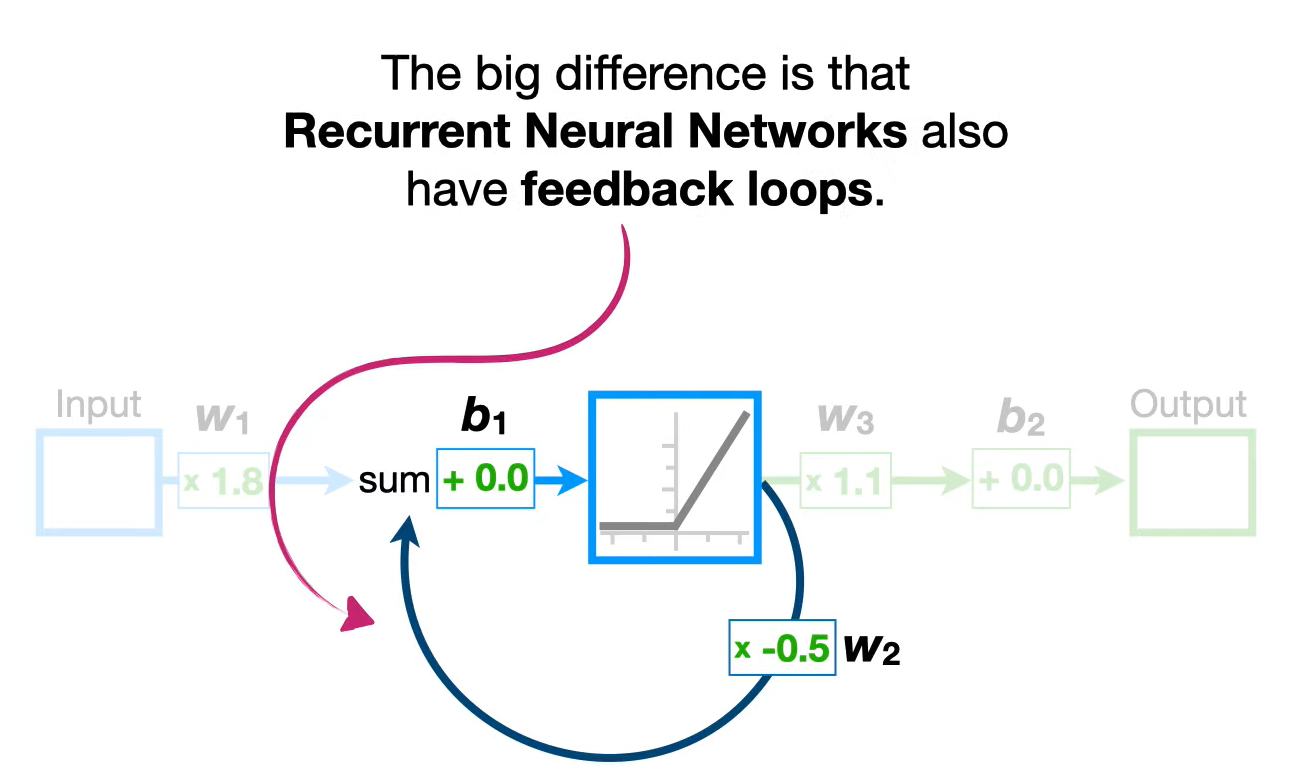

## 3. The Anatomy of an RNN: Unrolling the Loop

An RNN processes sequences by iterating through the sequence elements and maintaining a **hidden state** that contains information relative to what it has seen so far.

Instead of thinking of the feedback loop as a confusing circle, it is mathematically simpler to "unroll" the network through time. When we unroll an RNN, we create a copy of the network for each time step in our sequence.

### The Principle of Parameter Sharing
In our CNN lecturre, we used the same kernel across the entire image to find spatial features. RNNs apply the exact same principle, but across **time**.

No matter how many times we unroll the network (whether for a 3-day sequence or a 50-day sequence), the network uses the exact same weight matrices and biases at every single time step. We are not adding parameters; we are simply reusing them. This allows the model to generalize across sequences of any length.

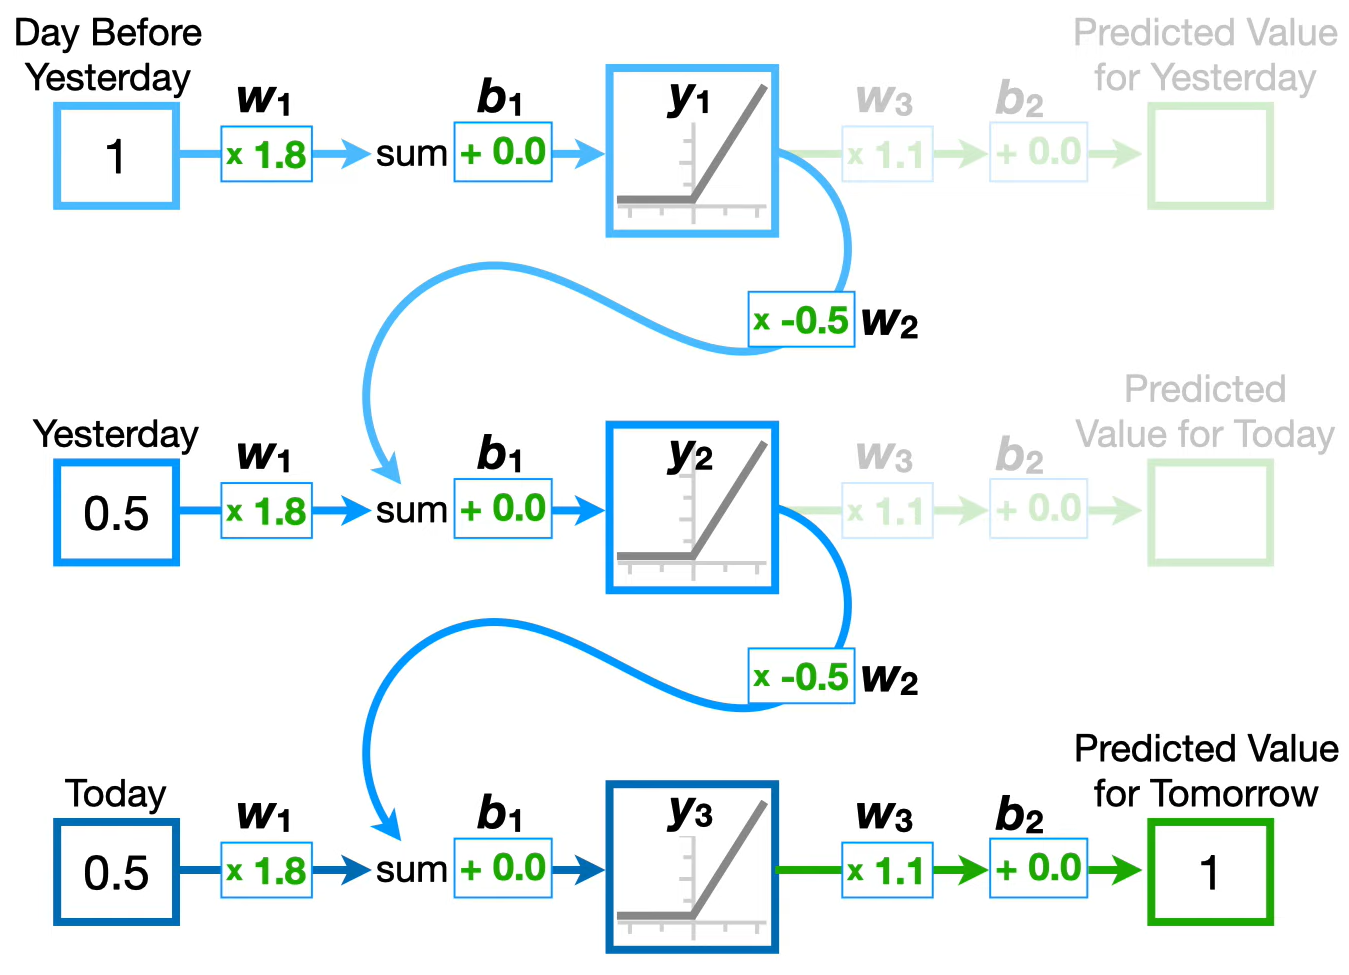

## 4. The Mathematics of the Forward Pass

to define the exact mathematical operations happening inside each unrolled step of our vanilla RNN. At any given time step $t$, the network receives two inputs:
1. The current data point: $x_t$ (e.g., today's stock price).
2. The previous hidden state: $h_{t-1}$ (the network's memory of the sequence so far).

The network must compute the new hidden state ($h_t$) and the current output prediction ($y_t$). We use three distinct weight matrices:
* $W_{xh}$: Weights connecting the input to the hidden state.
* $W_{hh}$: Recurrent weights connecting the previous hidden state to the current hidden state.
* $W_{hy}$: Weights connecting the hidden state to the output.

**Step 1: Updating the Hidden State**
We combine the current input and the previous memory using a linear combination, add a bias ($b_h$), and pass it through a non-linear activation function (typically $\tanh$ to keep values bound between -1 and 1).

$$h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b_h)$$

**Step 2: Generating the Output**
The prediction at time step $t$ is calculated directly from the newly updated hidden state.

$$y_t = W_{hy} h_t + b_y$$

This process repeats for every element in the sequence, allowing $h_t$ to act as a cumulative summary of the entire sequence up to time $t$.

## 5. Backpropagation Through Time (BPTT)

To train our RNN from scratch, we must update our weight matrices to minimize the error between our predictions ($y_t$) and the actual targets. Because the parameters are shared across all time steps, the gradient at a specific time step depends not only on the current error but also on the errors from previous time steps.

This algorithm is called **Backpropagation Through Time (BPTT)**.

*[Insert StatQuest exploding/vanishing gradient unrolled screenshot here]*

To find the gradient of the loss with respect to our recurrent weights ($W_{hh}$), we apply the chain rule backward from the final time step $T$ down to the first time step $t=0$.

The complexity arises because $h_t$ depends on $h_{t-1}$, which depends on $h_{t-2}$, and so on. The derivative of the loss with respect to $W_{hh}$ involves a product of Jacobians (the derivatives of each state with respect to the previous state):

$$\frac{\partial h_t}{\partial h_k} = \prod_{j=k+1}^t \frac{\partial h_j}{\partial h_{j-1}}$$

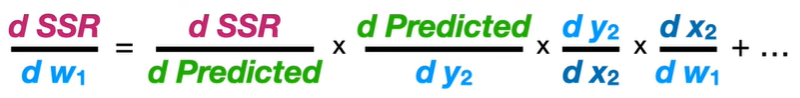

### The Exploding and Vanishing Gradient Problem
Because BPTT requires continuously multiplying these gradients together, we run into a major numerical stability issue:
* If the weights are slightly greater than 1, repeated multiplication causes the gradients to grow exponentially (**Exploding Gradients**), making training wildly unstable.
* If the weights are slightly less than 1, repeated multiplication causes the gradients to shrink to zero (**Vanishing Gradients**), meaning the network completely loses the ability to learn long-term dependencies.

For this project, we will implement gradient clipping to prevent explosions, but understanding this fundamental flaw is why architectures like LSTMs and Transformers were eventually invented.

In [3]:
#@title First the math helper functions since numpy is not allowed

import math
import random

random.seed(42)

def zeros(rows, cols):
    return [[0.0 for _ in range(cols)] for _ in range(rows)]

def random_matrix(rows, cols, scale=0.1):
    return [[(random.random() * 2 - 1) * scale for _ in range(cols)] for _ in range(rows)]

def add(A, B):
    return [[A[i][j] + B[i][j] for j in range(len(A[0]))] for i in range(len(A))]

def subtract(A, B):
    return [[A[i][j] - B[i][j] for j in range(len(A[0]))] for i in range(len(A))]

def scalar_multiply(A, scalar):
    return [[A[i][j] * scalar for j in range(len(A[0]))] for i in range(len(A))]

def dot(A, B):
    m, n, p = len(A), len(A[0]), len(B[0])
    result = zeros(m, p)
    for i in range(m):
        for j in range(p):
            for k in range(n):
                result[i][j] += A[i][k] * B[k][j]
    return result

def transpose(A):
    return [[A[j][i] for j in range(len(A))] for i in range(len(A[0]))]

def clip(A, min_val, max_val):
    return [[max(min_val, min(max_val, A[i][j])) for j in range(len(A[0]))] for i in range(len(A))]

def tanh(x):
    return math.tanh(x)

def tanh_deriv(x):
    return 1.0 - math.tanh(x)**2

def sigmoid(x):
    x = max(-709, min(709, x))
    return 1.0 / (1.0 + math.exp(-x))

def sigmoid_deriv(output_val):
    return output_val * (1.0 - output_val)

In [4]:
#@title The RNN architechture with forward and backward props

class VanillaRNN:
    def __init__(self, input_size, hidden_size, output_size):
        self.hidden_size = hidden_size

        # initializing the weights and biases with non zero values for weights and zeros for bias
        self.Wxh = random_matrix(hidden_size, input_size)  # input to hidden
        self.Whh = random_matrix(hidden_size, hidden_size) # hidden ho hidden which is the loop of the RNN
        self.Why = random_matrix(output_size, hidden_size) # hidden to output

        self.bh = zeros(hidden_size, 1) # hidden bias
        self.by = zeros(output_size, 1) # output bias

    def forward(self, inputs):

        # store state for backpropagation
        x, h, y = {}, {}, {}

        # initial hidden state (h_{-1}) is an array of zeros
        h[-1] = zeros(self.hidden_size, 1)

        for t in range(len(inputs)):
            # convert scalar input to a 1x1 matrix
            x[t] = [[inputs[t]]]

            # update Hidden State
            # h_t = tanh(Wxh * x_t + Whh * h_{t-1} + bh)
            term1 = dot(self.Wxh, x[t])
            term2 = dot(self.Whh, h[t-1])
            raw_h = add(add(term1, term2), self.bh)

            h[t] = [[tanh(val[0])] for val in raw_h]

            # calculate Output Prediction
            # y_t = Sigmoid(Why * h_t + by)   Ps: in our first trial we didn't use sigmoid and that resulted in negative predictions so we added the sigmoid to force the results between 0 and 1
            raw_y = add(dot(self.Why, h[t]), self.by)
            y[t] = [[sigmoid(val[0])] for val in raw_y]


        return x, h, y



    def backward(self, x, h, y, targets, learning_rate=0.01):
        # initialize gradients to zero
        dWxh, dWhh, dWhy = zeros(len(self.Wxh), len(self.Wxh[0])), zeros(len(self.Whh), len(self.Whh[0])), zeros(len(self.Why), len(self.Why[0]))
        dbh, dby = zeros(len(self.bh), 1), zeros(len(self.by), 1)

        # dh_next carries the gradient from the future backwards
        dh_next = zeros(self.hidden_size, 1)

        loss = 0.0

        # traverse sequence backwards (Unrolling backwards)
        for t in reversed(range(len(targets))):
            target_t = [[targets[t]]]

            # loss calculation (Mean Squared Error derivative)
            # derivative of MSE: 2 * (prediction - target)
            dy_raw = scalar_multiply(subtract(y[t], target_t), 2.0)
            loss += (y[t][0][0] - target_t[0][0])**2

            # backpropagate through the Sigmoid activation!
            # Chain Rule: dL/d(raw_y) = dL/dy * dy/d(raw_y)
            dy = zeros(len(y[t]), 1)
            for i in range(len(y[t])):
                dy[i][0] = dy_raw[i][0] * sigmoid_deriv(y[t][i][0])

            # output layer gradients
            dWhy = add(dWhy, dot(dy, transpose(h[t])))
            dby = add(dby, dy)

            # hidden layer gradient (Flows from current output AND next hidden state)
            dh = add(dot(transpose(self.Why), dy), dh_next)

            # backpropagate through tanh non-linearity
            dtanh = zeros(self.hidden_size, 1)
            for i in range(self.hidden_size):
                # dtanh = dh * (1 - h_t^2)
                dtanh[i][0] = dh[i][0] * (1.0 - h[t][i][0]**2)

            # hidden and Input weights gradients
            dWxh = add(dWxh, dot(dtanh, transpose(x[t])))
            dWhh = add(dWhh, dot(dtanh, transpose(h[t-1])))
            dbh = add(dbh, dtanh)

            # pass gradient backward to the previous time step
            dh_next = dot(transpose(self.Whh), dtanh)

        # apply Gradient Clipping (Crucial for preventing Exploding Gradients)
        clip_val = 5.0
        dWxh = clip(dWxh, -clip_val, clip_val)
        dWhh = clip(dWhh, -clip_val, clip_val)
        dWhy = clip(dWhy, -clip_val, clip_val)
        dbh = clip(dbh, -clip_val, clip_val)
        dby = clip(dby, -clip_val, clip_val)

        # gradient Descent Weight Update
        self.Wxh = subtract(self.Wxh, scalar_multiply(dWxh, learning_rate))
        self.Whh = subtract(self.Whh, scalar_multiply(dWhh, learning_rate))
        self.Why = subtract(self.Why, scalar_multiply(dWhy, learning_rate))
        self.bh = subtract(self.bh, scalar_multiply(dbh, learning_rate))
        self.by = subtract(self.by, scalar_multiply(dby, learning_rate))

        return loss / len(targets)

In [5]:
#@title Training the model

# model Parameters
input_features = 1    # 1 stock price in
hidden_nodes = 8      # Size of the "memory" state
output_features = 1   # 1 stock price out

rnn = VanillaRNN(input_size=input_features, hidden_size=hidden_nodes, output_size=output_features)

# using the generator we made earlier to create a long training sequence
seq_length = 500
training_data = generate_sequence(seq_length, [0.0, 0.0])

# we use past context to predict the immediate next step. for example, context length of 4 days to predict day 5.
context_length = 6
epochs = 800
learning_rate = 0.01

# training Loop
for epoch in range(epochs):
    epoch_loss = 0

    # slide a window across the training data using the context length
    for i in range(len(training_data) - context_length - 1):
        # extract sequence and target
        inputs = training_data[i : i + context_length]

        # the targets are the sequence shifted by one time step into the future
        targets = training_data[i + 1 : i + context_length + 1]

        # forward Pass
        x, h, y = rnn.forward(inputs)

        # backward Pass and weight updat
        loss = rnn.backward(x, h, y, targets, learning_rate)
        epoch_loss += loss

    if epoch % 50 == 0:
        avg_loss = epoch_loss / (len(training_data) - context_length)
        print(f"Epoch {epoch} | Average Loss: {avg_loss:.4f}")

Epoch 0 | Average Loss: 0.1975
Epoch 50 | Average Loss: 0.0895
Epoch 100 | Average Loss: 0.0848
Epoch 150 | Average Loss: 0.0844
Epoch 200 | Average Loss: 0.0841
Epoch 250 | Average Loss: 0.0839
Epoch 300 | Average Loss: 0.0838
Epoch 350 | Average Loss: 0.0835
Epoch 400 | Average Loss: 0.0832
Epoch 450 | Average Loss: 0.0829
Epoch 500 | Average Loss: 0.0829
Epoch 550 | Average Loss: 0.0829
Epoch 600 | Average Loss: 0.0828
Epoch 650 | Average Loss: 0.0828
Epoch 700 | Average Loss: 0.0828
Epoch 750 | Average Loss: 0.0828


In [6]:
#@title testing the model

# test rule 1: The surge (0.0, 0.0, 0.0, 0.5) ==> should predict 1.0
_, _, test_y1 = rnn.forward([0.0, 0.0, 0.0, 0.5])
pred1 = test_y1[3][0][0]
print(f"surge rule: predicted {pred1:.2f} | should be around 1.0")

# test rule 2: The crash (1.0, 1.0, 1.0, 0.5) ==> should predict 0.0
_, _, test_y2 = rnn.forward([1.0, 1.0, 1.0, 0.5])
pred2 = test_y2[3][0][0]
print(f"crash rule: predicted {pred2:.2f} | should be around 0.0")

# test rule 3: the ceiling (1.0, 1.0, 1.0, 1.0) ==> should predict 1.0
_, _, test_y3 = rnn.forward([1.0, 1.0, 1.0, 1.0])
pred3 = test_y3[3][0][0]
print(f"ceiling Rule: predicted {pred3:.2f} | should be around 1.0")

surge rule: predicted 0.98 | should be around 1.0
crash rule: predicted 0.01 | should be around 0.0
ceiling Rule: predicted 0.87 | should be around 1.0


## 6. Setting Up a Proper Experiment

So far, we only checked our network with three hand-picked examples (the surge, the crash and the ceiling). That is useful to see that the network learned *those rules*, but it does not tell us how good the network actually is. From this point on we continue the project like a real experiment, and we need three things before we can compare anything.

### 1. Separate train / validation / test sequences
* **Training set:** the sequences the weights are updated on.
* **Validation set:** sequences we use to watch the learning curves and to choose hyperparameters (hidden size, optimizer...).
* **Test set:** sequences we only look at for the final numbers.

**Why separate *sequences* and not just a random split of windows?** We train on sliding windows, and two neighbouring windows share 5 of their 6 days. If we randomly split the windows, almost every test window would have a near-identical twin in the training set, and the test loss would look better than it really is. This is called **data leakage**. By generating different sequences for every split, no day of the test set is ever seen during training.

### 2. More than one metric
* **MSE:** the same loss we train on (it punishes big mistakes).
* **MAE:** the average absolute mistake, easier to read as "how far off are we on average".
* **State accuracy:** we snap the prediction to the closest of Low / Medium / High and check if it is the correct state.

### 3. Baselines and a noise floor
A test loss of 0.07 means nothing on its own. We need reference points:
* **Mean:** always predict the average price.
* **Persistence:** tomorrow will be the same as today.
* **Markov-2 table:** a lookup table that only looks at (yesterday, today). If a model beats this one, it is using more than two days of memory.
* **Oracle:** a predictor that knows the generating rules exactly. Remember that three of our transitions are *random* (for example 0.5 $\rightarrow$ ?). No model can predict a coin flip, so even a perfect model has an error above zero. The oracle tells us exactly how big this unavoidable error is, and that is why our first RNN's loss stopped at around 0.083 and never went to zero.

All the hyperparameters are collected in one configuration cell, so every experiment below uses the same numbers unless we say otherwise.

In [7]:
#@title Configuration: every hyperparameter in one place

import time

# data
n_train_sequences = 8     # separate sequences for training
n_val_sequences = 4       # separate sequences for validation (used while tuning / watching curves)
n_test_sequences = 10     # separate sequences that are only touched for the final numbers
sequence_length = 64      # length of every generated sequence
context_length = 6        # same context length we used for the first RNN

# model
hidden_nodes = 8          # same memory size as the first RNN
mlp_hidden_nodes = 11     # chosen so the MLP has exactly the same number of parameters as the RNN (89)

# training
exp_epochs = 100          # epochs for every experiment (the first RNN plateaued around epoch 100)
learning_rate = 0.01      # same learning rate as the first RNN
clip_val = 5.0            # same clipping value as the first RNN
adam_epochs = 40          # Adam gets to the plateau much faster than plain SGD (see the optimizer section)
adam_lr = 0.01
eval_every = 5            # how often we measure train / val loss for the curves

states = [0.0, 0.5, 1.0]  # the three price levels

In [8]:
#@title Dataset helpers: separate sequences for train / validation / test

def set_seed(seed):
    random.seed(seed)

def make_dataset(n_sequences, length):
    # every sequence starts from a random pair of states so that all 9 possible (yesterday, today) pairs show up
    sequences = []
    for _ in range(n_sequences):
        start = [random.choice(states), random.choice(states)]
        sequences.append(generate_sequence(length, start))
    return sequences

def make_windows(sequences, context, truths=None):
    # windows are cut INSIDE each sequence only, so no window ever mixes two sequences
    # and no sequence is shared between train / val / test.
    # inputs come from "sequences", targets come from "truths" (same thing unless the inputs are corrupted)
    if truths is None:
        truths = sequences
    windows = []
    for seq, truth in zip(sequences, truths):
        for i in range(len(seq) - context):
            inputs = seq[i : i + context]
            targets = truth[i + 1 : i + context + 1]
            windows.append((inputs, targets))
    return windows

set_seed(1)
train_sequences = make_dataset(n_train_sequences, sequence_length)
val_sequences = make_dataset(n_val_sequences, sequence_length)
test_sequences = make_dataset(n_test_sequences, sequence_length)

train_windows = make_windows(train_sequences, context_length)
val_windows = make_windows(val_sequences, context_length)
test_windows = make_windows(test_sequences, context_length)

print(f"train: {len(train_sequences)} sequences -> {len(train_windows)} windows")
print(f"val:   {len(val_sequences)} sequences -> {len(val_windows)} windows")
print(f"test:  {len(test_sequences)} sequences -> {len(test_windows)} windows")

train: 8 sequences -> 464 windows
val:   4 sequences -> 232 windows
test:  10 sequences -> 580 windows


In [9]:
#@title Evaluation: metrics + simple baselines + the "oracle" noise floor

def to_state(value):
    # snap a continuous prediction to the closest of Low (0.0) / Medium (0.5) / High (1.0)
    return min(states, key=lambda s: abs(s - value))

def evaluate(model, windows):
    # every model has to answer the same question: given a window of days, what is the NEXT day?
    # so we only score the prediction made at the last step of each window (the one that saw the full context)
    squared, absolute, correct = 0.0, 0.0, 0
    for inputs, targets in windows:
        pred = model.predict_sequence(inputs)[-1]
        target = targets[-1]
        squared += (pred - target) ** 2
        absolute += abs(pred - target)
        correct += 1 if to_state(pred) == to_state(target) else 0
    n = len(windows)
    return {'mse': squared / n, 'mae': absolute / n, 'acc': correct / n}

class PersistenceBaseline:
    # "tomorrow will look like today"
    def predict_sequence(self, inputs):
        return list(inputs)

class MeanBaseline:
    # always predicts the average price of the training data
    def __init__(self, sequences):
        flat = [v for seq in sequences for v in seq]
        self.mean = sum(flat) / len(flat)
    def predict_sequence(self, inputs):
        return [self.mean for _ in inputs]

class Markov2Baseline:
    # the best predictor that only looks at (yesterday, today): a lookup table filled with the average next value
    # seen in the training data. if a model beats this one, it is using more than 2 days of memory
    def __init__(self, sequences, truths=None):
        truths = truths if truths is not None else sequences
        sums, counts = {}, {}
        for seq, truth in zip(sequences, truths):
            for t in range(1, len(seq) - 1):
                key = (to_state(seq[t - 1]), to_state(seq[t]))
                sums[key] = sums.get(key, 0.0) + truth[t + 1]
                counts[key] = counts.get(key, 0) + 1
        self.table = {key: sums[key] / counts[key] for key in sums}
        self.default = 0.5

    def predict_sequence(self, inputs):
        preds = [self.default]
        for t in range(1, len(inputs)):
            preds.append(self.table.get((to_state(inputs[t - 1]), to_state(inputs[t])), self.default))
        return preds

class OracleBaseline:
    # knows the generating rules exactly, so it predicts the EXPECTED next value given (yesterday, today).
    # no model can beat it, so its error is the noise floor of the dataset
    def expected_next(self, yesterday, today, regime='A'):
        # (regime B is the "contrarian market" we introduce later in the notebook, ignore it for now)
        if regime == 'A':
            if yesterday == 0.0 and today == 0.0:
                return 0.8 * 0.0 + 0.2 * 0.5      # the floor
            if yesterday == 0.0 and today == 0.5:
                return 1.0                          # the surge
            if yesterday == 1.0 and today == 0.5:
                return 0.0                          # the crash
            if yesterday == 1.0 and today == 1.0:
                return 0.8 * 1.0 + 0.2 * 0.5        # the ceiling
        else:
            if yesterday == 0.0 and today == 0.0:
                return 0.8 * 1.0 + 0.2 * 0.5
            if yesterday == 0.0 and today == 0.5:
                return 0.0
            if yesterday == 1.0 and today == 0.5:
                return 1.0
            if yesterday == 1.0 and today == 1.0:
                return 0.8 * 0.0 + 0.2 * 0.5
        return (0.0 + 0.5 + 1.0) / 3            # random walk: any of the 3 states is equally likely

    def predict_sequence(self, inputs):
        preds = [0.5]  # with a single day of history it can only guess the middle
        for t in range(1, len(inputs)):
            preds.append(self.expected_next(inputs[t - 1], inputs[t]))
        return preds

def print_table(headers, rows):
    widths = [max(len(str(headers[i])), *(len(str(r[i])) for r in rows)) for i in range(len(headers))]
    print(' | '.join(str(h).ljust(widths[i]) for i, h in enumerate(headers)))
    print('-+-'.join('-' * w for w in widths))
    for r in rows:
        print(' | '.join(str(v).ljust(widths[i]) for i, v in enumerate(r)))

baselines = {
    'Mean': MeanBaseline(train_sequences),
    'Persistence': PersistenceBaseline(),
    'Markov-2 table': Markov2Baseline(train_sequences),
    'Oracle': OracleBaseline(),
}

rows = []
for name, model in baselines.items():
    r = evaluate(model, test_windows)
    rows.append([name, f"{r['mse']:.4f}", f"{r['mae']:.4f}", f"{r['acc'] * 100:.1f}%"])
print_table(['Baseline', 'Test MSE', 'Test MAE', 'State accuracy'], rows)

Baseline       | Test MSE | Test MAE | State accuracy
---------------+----------+----------+---------------
Mean           | 0.1943   | 0.4026   | 19.7%         
Persistence    | 0.1806   | 0.2784   | 52.6%         
Markov-2 table | 0.0680   | 0.1858   | 71.0%         
Oracle         | 0.0673   | 0.1767   | 71.0%         


### What the baselines tell us
* **Persistence** (MSE 0.181) and **Mean** (0.194) are far from the floor, so a model has to learn something real to beat them.
* The **Oracle** has a test MSE of **0.067** and a state accuracy of **71%**. That is the best any model can do on this environment. The randomness of 5 of the 9 transitions makes it impossible to reach 0 or 100%.
* The **Markov-2 table** is almost as good as the oracle (0.068). This makes sense: the environment *is* a "two days of memory" process, so a table indexed by (yesterday, today) captures everything. It will be useful later as a yardstick for "is the model using more than two days?".

## 7. Making the Code Reusable

The `VanillaRNN` class we wrote earlier does a forward pass and a backward pass, and then **updates the weights inside `backward`** with plain gradient descent. That was perfect to learn how BPTT works, but it blocks several of the experiments we want to run. So we make four changes, and we keep the original class untouched.

1. **`TrainableRNN`:** a subclass of `VanillaRNN`. It reuses the exact same forward pass and the exact same BPTT maths, but `loss_and_grads` *returns* the gradients instead of applying them. Why? Because (a) we want to try different optimizers and (b) we want to look at the gradients themselves later. (We check below that it gives exactly the same update as the original.)
2. **`MLP`:** the feedforward baseline. It gets the full six-day window as one vector of 6 numbers and predicts the next day. **Why 11 hidden units?** The RNN with 8 hidden units has 89 parameters. An MLP with 11 hidden units also has exactly 89, so if one model wins it is not because it is bigger.
3. **Optimizers:** SGD, SGD with momentum, RMSprop and Adam, all written with plain Python lists like everything else. The `SGD` class is exactly the update we used inside the first RNN.
4. **A reusable training loop:** it is the same loop as before (one window at a time, same gradient clipping), with two small differences: the windows are shuffled every epoch (so the order of the data cannot bias the weights), and the train / validation loss are measured every few epochs for the learning curves.

Also notice that we keep **no numpy** and we only add the few helpers we were missing (element-wise multiplication, stacking vectors, the norm of a matrix).

In [10]:
#@title A few more math helpers (still no numpy) + the models we will compare

def hadamard(A, B):
    # element-wise product (needed for the LSTM gates)
    return [[A[i][j] * B[i][j] for j in range(len(A[0]))] for i in range(len(A))]

def apply_fn(A, fn):
    return [[fn(A[i][j]) for j in range(len(A[0]))] for i in range(len(A))]

def vstack(A, B):
    # stack two column vectors on top of each other
    return [row[:] for row in A] + [row[:] for row in B]

def norm(A):
    # euclidean norm of a matrix / vector (we use it to measure the size of gradients)
    return math.sqrt(sum(A[i][j] ** 2 for i in range(len(A)) for j in range(len(A[0]))))

def count_parameters(model):
    return sum(len(P) * len(P[0]) for P in model.parameters().values())


class TrainableRNN(VanillaRNN):
    # exactly the same network as before (same forward pass, same BPTT maths).
    # the only change: the backward pass RETURNS the gradients instead of updating the weights right away.
    # this lets us (1) plug in any optimizer and (2) look at the gradients themselves

    def parameters(self):
        return {'Wxh': self.Wxh, 'Whh': self.Whh, 'Why': self.Why, 'bh': self.bh, 'by': self.by}

    @classmethod
    def from_trained(cls, trained):
        # wrap an already trained VanillaRNN (shares the same weights, nothing is copied)
        model = cls(len(trained.Wxh[0]), trained.hidden_size, len(trained.Why))
        model.Wxh, model.Whh, model.Why = trained.Wxh, trained.Whh, trained.Why
        model.bh, model.by = trained.bh, trained.by
        return model

    def predict_sequence(self, inputs):
        _, _, y = self.forward(inputs)
        return [y[t][0][0] for t in range(len(inputs))]

    def loss_and_grads(self, inputs, targets, last_only=False):
        # last_only=True: only the final time step is supervised (used for the memory stress test)
        x, h, y = self.forward(inputs)

        grads = {
            'Wxh': zeros(len(self.Wxh), len(self.Wxh[0])),
            'Whh': zeros(len(self.Whh), len(self.Whh[0])),
            'Why': zeros(len(self.Why), len(self.Why[0])),
            'bh': zeros(len(self.bh), 1),
            'by': zeros(len(self.by), 1),
        }
        dh_next = zeros(self.hidden_size, 1)
        loss = 0.0

        for t in reversed(range(len(targets))):
            target_t = [[targets[t]]]
            weight = 1.0 if (not last_only or t == len(targets) - 1) else 0.0
            dy_raw = scalar_multiply(subtract(y[t], target_t), 2.0 * weight)
            loss += weight * (y[t][0][0] - target_t[0][0]) ** 2

            dy = zeros(len(y[t]), 1)
            for i in range(len(y[t])):
                dy[i][0] = dy_raw[i][0] * sigmoid_deriv(y[t][i][0])

            grads['Why'] = add(grads['Why'], dot(dy, transpose(h[t])))
            grads['by'] = add(grads['by'], dy)

            dh = add(dot(transpose(self.Why), dy), dh_next)

            dtanh = zeros(self.hidden_size, 1)
            for i in range(self.hidden_size):
                dtanh[i][0] = dh[i][0] * (1.0 - h[t][i][0] ** 2)

            grads['Wxh'] = add(grads['Wxh'], dot(dtanh, transpose(x[t])))
            grads['Whh'] = add(grads['Whh'], dot(dtanh, transpose(h[t - 1])))
            grads['bh'] = add(grads['bh'], dtanh)

            dh_next = dot(transpose(self.Whh), dtanh)

        return loss / (1 if last_only else len(targets)), grads


class MLP:
    # the feedforward baseline: it receives the whole window at once as a fixed-size vector
    # (6 numbers) and predicts ONE value, the next day. no hidden state, no loop.
    def __init__(self, input_size, hidden_size, output_size=1):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.W1 = random_matrix(hidden_size, input_size)
        self.b1 = zeros(hidden_size, 1)
        self.W2 = random_matrix(output_size, hidden_size)
        self.b2 = zeros(output_size, 1)

    def parameters(self):
        return {'W1': self.W1, 'b1': self.b1, 'W2': self.W2, 'b2': self.b2}

    def forward(self, window):
        x = [[v] for v in window]
        h = apply_fn(add(dot(self.W1, x), self.b1), tanh)
        y = apply_fn(add(dot(self.W2, h), self.b2), sigmoid)
        return x, h, y

    def predict_sequence(self, inputs):
        # an MLP can only look at exactly input_size days. for a longer sequence the only thing we can do
        # is slide the window along it. (before we have enough days the window is padded with zeros,
        # which is the same thing the RNN does with its zero initial hidden state)
        preds = []
        for t in range(len(inputs)):
            window = inputs[max(0, t - self.input_size + 1) : t + 1]
            window = [0.0] * (self.input_size - len(window)) + window
            preds.append(self.forward(window)[2][0][0])
        return preds

    def loss_and_grads(self, inputs, targets, last_only=True):
        # the MLP only predicts the day after the window, so only the last target matters
        # a fixed-size network can only look at the last input_size days (shorter inputs are padded with zeros)
        inputs = inputs[-self.input_size:]
        inputs = [0.0] * (self.input_size - len(inputs)) + list(inputs)
        x, h, y = self.forward(inputs)
        target = targets[-1]
        loss = (y[0][0] - target) ** 2

        dy = [[2.0 * (y[0][0] - target) * sigmoid_deriv(y[0][0])]]
        dh = dot(transpose(self.W2), dy)
        dtanh = [[dh[i][0] * (1.0 - h[i][0] ** 2)] for i in range(self.hidden_size)]

        grads = {
            'W2': dot(dy, transpose(h)),
            'b2': dy,
            'W1': dot(dtanh, transpose(x)),
            'b1': dtanh,
        }
        return loss, grads


rnn_check = TrainableRNN(input_features, hidden_nodes, output_features)
mlp_check = MLP(context_length, mlp_hidden_nodes)
print(f"parameters | Vanilla RNN (8 hidden): {count_parameters(rnn_check)} | MLP (11 hidden): {count_parameters(mlp_check)}")

parameters | Vanilla RNN (8 hidden): 89 | MLP (11 hidden): 89


In [11]:
#@title Optimizers, the training loop and plotting helpers

class SGD:
    # plain gradient descent: this is exactly the update rule used inside the first VanillaRNN.backward
    def __init__(self, lr=0.01):
        self.lr = lr

    def step(self, params, grads):
        for name in params:
            P, G = params[name], grads[name]
            for i in range(len(P)):
                for j in range(len(P[0])):
                    P[i][j] -= self.lr * G[i][j]


class SGDMomentum:
    # keeps a running "velocity" of the gradients so that consistent directions speed up and noisy ones cancel
    def __init__(self, lr=0.01, momentum=0.9):
        self.lr, self.momentum = lr, momentum
        self.v = {}

    def step(self, params, grads):
        for name in params:
            P, G = params[name], grads[name]
            if name not in self.v:
                self.v[name] = zeros(len(P), len(P[0]))
            V = self.v[name]
            for i in range(len(P)):
                for j in range(len(P[0])):
                    V[i][j] = self.momentum * V[i][j] + G[i][j]
                    P[i][j] -= self.lr * V[i][j]


class RMSprop:
    # divides every step by a running average of the recent gradient magnitude of that weight
    def __init__(self, lr=0.01, rho=0.9, eps=1e-8):
        self.lr, self.rho, self.eps = lr, rho, eps
        self.s = {}

    def step(self, params, grads):
        for name in params:
            P, G = params[name], grads[name]
            if name not in self.s:
                self.s[name] = zeros(len(P), len(P[0]))
            S = self.s[name]
            for i in range(len(P)):
                for j in range(len(P[0])):
                    S[i][j] = self.rho * S[i][j] + (1 - self.rho) * G[i][j] ** 2
                    P[i][j] -= self.lr * G[i][j] / (math.sqrt(S[i][j]) + self.eps)


class Adam:
    # momentum + RMSprop together, with bias correction for the first steps
    def __init__(self, lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m, self.v, self.t = {}, {}, 0

    def step(self, params, grads):
        self.t += 1
        correction1 = 1 - self.beta1 ** self.t
        correction2 = 1 - self.beta2 ** self.t
        for name in params:
            P, G = params[name], grads[name]
            if name not in self.m:
                self.m[name] = zeros(len(P), len(P[0]))
                self.v[name] = zeros(len(P), len(P[0]))
            M, V = self.m[name], self.v[name]
            for i in range(len(P)):
                for j in range(len(P[0])):
                    M[i][j] = self.beta1 * M[i][j] + (1 - self.beta1) * G[i][j]
                    V[i][j] = self.beta2 * V[i][j] + (1 - self.beta2) * G[i][j] ** 2
                    m_hat = M[i][j] / correction1
                    v_hat = V[i][j] / correction2
                    P[i][j] -= self.lr * m_hat / (math.sqrt(v_hat) + self.eps)


def clip_grads(grads, clip_value):
    # same element-wise clipping as the first RNN (clip_value=None switches it off)
    if clip_value is None:
        return grads
    return {name: clip(G, -clip_value, clip_value) for name, G in grads.items()}


def train(model, optimizer, train_windows, val_windows, epochs=exp_epochs, clip_value=clip_val,
          eval_every=eval_every, verbose=False, seed=0, last_only=False):
    # the same loop as the first training cell (one window at a time), but:
    #  - the windows are shuffled every epoch
    #  - the update is done by an optimizer object
    #  - train / val loss are measured on the same question (next day after the window) every few epochs
    history = {'epoch': [], 'train_mse': [], 'val_mse': [], 'seconds': 0.0}
    params = model.parameters()
    order = list(range(len(train_windows)))
    shuffler = random.Random(seed)
    start = time.time()

    for epoch in range(1, epochs + 1):
        shuffler.shuffle(order)
        for idx in order:
            inputs, targets = train_windows[idx]
            _, grads = model.loss_and_grads(inputs, targets, last_only=last_only)
            optimizer.step(params, clip_grads(grads, clip_value))

        if epoch == 1 or epoch % eval_every == 0 or epoch == epochs:
            train_mse = evaluate(model, train_windows)['mse']
            val_mse = evaluate(model, val_windows)['mse']
            history['epoch'].append(epoch)
            history['train_mse'].append(train_mse)
            history['val_mse'].append(val_mse)
            if verbose and (epoch == 1 or epoch % (eval_every * 4) == 0 or epoch == epochs):
                print(f"Epoch {epoch} | Train MSE: {train_mse:.4f} | Val MSE: {val_mse:.4f}")

    history['seconds'] = time.time() - start
    return history


def run_experiment(build_model, build_optimizer, train_windows, val_windows, test_windows,
                   seed=0, epochs=exp_epochs, clip_value=clip_val, verbose=False, last_only=False, eval_every=eval_every):
    # build -> train -> evaluate on all three splits, and give everything back in one dictionary
    set_seed(seed)
    model = build_model()
    optimizer = build_optimizer()
    history = train(model, optimizer, train_windows, val_windows, epochs=epochs,
                    clip_value=clip_value, verbose=verbose, seed=seed, last_only=last_only,
                    eval_every=eval_every)
    return {
        'model': model,
        'history': history,
        'params': count_parameters(model),
        'train': evaluate(model, train_windows),
        'val': evaluate(model, val_windows),
        'test': evaluate(model, test_windows),
    }


def stepwise_errors(model, observed_sequences, truth_sequences):
    # runs the model ONCE over every full sequence (for an RNN the hidden state just keeps going) and returns
    # the average squared error at every position: error[t] = (prediction after day t  -  true value of day t+1)^2
    length = len(observed_sequences[0])
    totals = [0.0] * (length - 1)
    for obs, truth in zip(observed_sequences, truth_sequences):
        preds = model.predict_sequence(obs)
        for t in range(length - 1):
            totals[t] += (preds[t] - truth[t + 1]) ** 2
    return [v / len(observed_sequences) for v in totals]


def mean_std(values):
    mean = sum(values) / len(values)
    std = math.sqrt(sum((v - mean) ** 2 for v in values) / len(values))
    return mean, std


def plot_curves(histories, title, ylim=None):
    # histories: {label: history}. solid line = train, dashed line = validation
    fig, ax = plt.subplots(1, 1, figsize=(10, 5))
    colors = ['blue', 'green', 'red', 'orange', 'purple', 'brown']
    for (label, hist), color in zip(histories.items(), colors):
        ax.plot(hist['epoch'], hist['train_mse'], color=color, linestyle='-', linewidth=2, label=f'{label} (train)')
        ax.plot(hist['epoch'], hist['val_mse'], color=color, linestyle='--', linewidth=2, label=f'{label} (val)')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Epochs')
    ax.set_ylabel('MSE')
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()
    plt.tight_layout()
    plt.show()


def plot_predictions(models, sequence, title, start=0, end=40, context=context_length):
    # for every day we ask each model: "given the last `context` days, what is tomorrow?" and plot it against the truth
    fig, ax = plt.subplots(1, 1, figsize=(12, 5))
    days = list(range(start + 1, end + 1))
    ax.plot(days, sequence[start + 1 : end + 1], marker='o', linestyle='-', color='black', linewidth=2, label='Ground truth')
    colors = ['blue', 'red', 'green', 'orange', 'purple']
    for (label, model), color in zip(models.items(), colors):
        preds = []
        for t in range(start, end):
            window = sequence[max(0, t - context + 1) : t + 1]
            preds.append(model.predict_sequence(window)[-1])
        ax.plot(days, preds, marker='x', linestyle='--', color=color, linewidth=1.5, label=label)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Days')
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.set_yticklabels(['Low (0.0)', 'Medium (0.5)', 'High (1.0)'])
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()
    plt.tight_layout()
    plt.show()


def error_by_transition(model, windows):
    # splits the test error by the last two days, so we can see WHICH rules the model has learned
    # and which parts of the data are just random (and therefore unpredictable for everybody)
    oracle = OracleBaseline()
    groups = {}
    for inputs, targets in windows:
        key = (inputs[-2], inputs[-1])
        pred = model.predict_sequence(inputs)[-1]
        groups.setdefault(key, []).append((pred, targets[-1]))
    rows = []
    for key in sorted(groups):
        pairs = groups[key]
        n = len(pairs)
        mse = sum((p - t) ** 2 for p, t in pairs) / n
        rows.append([f"{key[0]} -> {key[1]}", n, f"{sum(t for _, t in pairs) / n:.2f}",
                     f"{sum(p for p, _ in pairs) / n:.2f}", f"{mse:.4f}",
                     f"{sum((oracle.expected_next(*key) - t) ** 2 for _, t in pairs) / n:.4f}"])
    print_table(['(yesterday -> today)', 'Windows', 'Avg truth', 'Avg prediction', 'Model MSE', 'Oracle MSE'], rows)

def average_runs(runs):
    # averages the metrics of the same experiment repeated with different random seeds
    def avg(getter):
        return sum(getter(r) for r in runs) / len(runs)
    return {
        'params': runs[0]['params'],
        'seconds': avg(lambda r: r['history']['seconds']),
        'train': {'mse': avg(lambda r: r['train']['mse'])},
        'val': {'mse': avg(lambda r: r['val']['mse'])},
        'test': {'mse': avg(lambda r: r['test']['mse']), 'mae': avg(lambda r: r['test']['mae']),
                 'acc': avg(lambda r: r['test']['acc'])},
        'test_mse_std': mean_std([r['test']['mse'] for r in runs])[1],
    }

results = []  # every experiment adds a line here, we print the whole thing in the results section at the end

def log_result(experiment, name, r):
    results.append([experiment, name, r['params'], f"{r['train']['mse']:.4f}", f"{r['val']['mse']:.4f}",
                    f"{r['test']['mse']:.4f}", f"{r['test']['mae']:.4f}", f"{r['test']['acc'] * 100:.1f}%"])

In [12]:
#@title Sanity check: does TrainableRNN + SGD do exactly what the original VanillaRNN.backward did?

random.seed(3)
original = VanillaRNN(1, 8, 1)
random.seed(3)
refactored = TrainableRNN(1, 8, 1)

example_inputs = [0.0, 0.5, 1.0, 1.0, 0.5, 0.0]
example_targets = [0.5, 1.0, 1.0, 0.5, 0.0, 0.0]

x, h, y = original.forward(example_inputs)
original.backward(x, h, y, example_targets, 0.01)

loss, grads = refactored.loss_and_grads(example_inputs, example_targets)
SGD(0.01).step(refactored.parameters(), clip_grads(grads, 5.0))

largest_difference = max(abs(original.Whh[i][j] - refactored.Whh[i][j]) for i in range(8) for j in range(8))
print(f"largest difference in Whh after one update: {largest_difference}")

largest difference in Whh after one update: 0.0


## 8. Evaluating the RNN We Already Trained

Before building anything new, let's grade the RNN from section 5 properly. Remember, it was trained for 800 epochs on **one** long sequence that started at the floor, and we only tested it on 3 hand-picked inputs. Now we test it on 10 brand new sequences it has never seen.

We look at three things:
1. The metrics next to the baselines.
2. **Error by transition:** the test error split by the last two days. This tells us *which rules* were learned and where the error comes from.
3. A **prediction vs. ground truth** plot.

In [13]:
#@title Evaluating the first RNN on the held-out test sequences

first_rnn = TrainableRNN.from_trained(rnn)   # same weights as the rnn we trained in section 5, just wrapped so evaluate() can use it

rows = []
for name, model in list(baselines.items()) + [('First RNN (section 5)', first_rnn)]:
    r = evaluate(model, test_windows)
    rows.append([name, f"{r['mse']:.4f}", f"{r['mae']:.4f}", f"{r['acc'] * 100:.1f}%"])
print_table(['Model', 'Test MSE', 'Test MAE', 'State accuracy'], rows)

print()
error_by_transition(first_rnn, test_windows)

Model                 | Test MSE | Test MAE | State accuracy
----------------------+----------+----------+---------------
Mean                  | 0.1943   | 0.4026   | 19.7%         
Persistence           | 0.1806   | 0.2784   | 52.6%         
Markov-2 table        | 0.0680   | 0.1858   | 71.0%         
Oracle                | 0.0673   | 0.1767   | 71.0%         
First RNN (section 5) | 0.0793   | 0.2004   | 70.9%         

(yesterday -> today) | Windows | Avg truth | Avg prediction | Model MSE | Oracle MSE
---------------------+---------+-----------+----------------+-----------+-----------
0.0 -> 0.0           | 102     | 0.14      | 0.10           | 0.0523    | 0.0526    
0.0 -> 0.5           | 52      | 1.00      | 0.99           | 0.0003    | 0.0000    
0.0 -> 1.0           | 30      | 0.55      | 0.62           | 0.1812    | 0.1083    
0.5 -> 0.0           | 62      | 0.52      | 0.48           | 0.1970    | 0.1815    
0.5 -> 1.0           | 51      | 0.60      | 0.40           | 

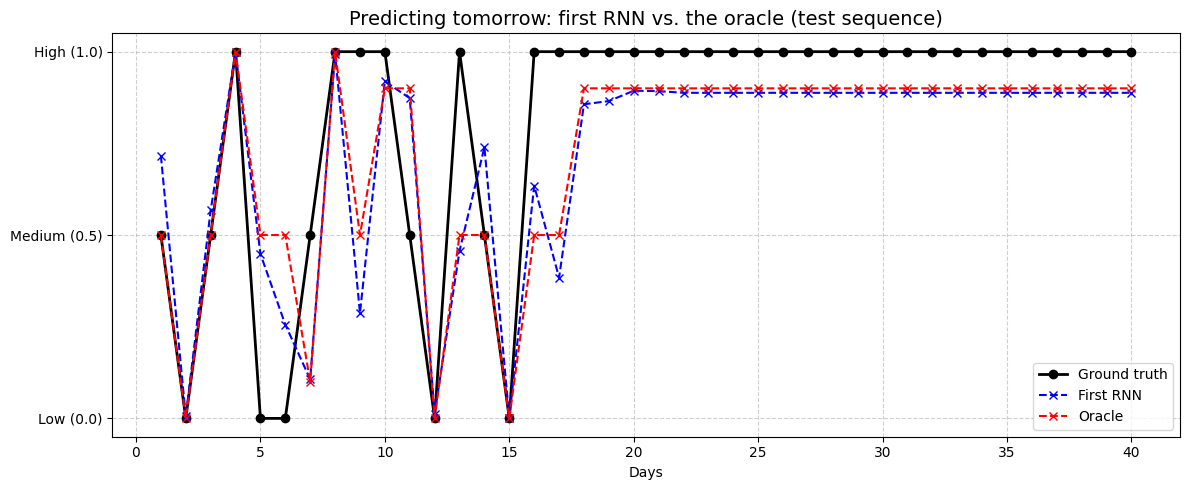

In [14]:
#@title Prediction vs. ground truth

plot_predictions({'First RNN': first_rnn, 'Oracle': OracleBaseline()}, test_sequences[0],
                 'Predicting tomorrow: first RNN vs. the oracle (test sequence)')

### What we see
* On sequences it has never seen, the first RNN gets a test MSE of **0.079** and **70.9%** accuracy. The oracle gets 0.067 and 71.0%, so the RNN is **almost as good as it can possibly be** in terms of accuracy. The extra 0.012 of MSE is the part that can still be learned.
* The **error by transition** table shows where it comes from. On the two deterministic rules (0.0 $\rightarrow$ 0.5 and 1.0 $\rightarrow$ 0.5) the average prediction is 0.99 and 0.01, with an MSE of 0.0003: the surge and the crash are learned perfectly. The floor (0.0 $\rightarrow$ 0.0) and the ceiling (1.0 $\rightarrow$ 1.0) are also at the oracle's level.
* The remaining gap is on the *random* transitions (for example 0.5 $\rightarrow$ 1.0: truth averages 0.60 but the RNN predicts 0.40). A likely reason is that this RNN was trained on **one** sequence, and a single sequence contains few examples of these pairs, so the network does not see enough of them to estimate their average well. We did not count them, so this is our best guess and not a verified fact. The held-out test is exactly what exposes this, and our 3 hand-picked examples could not.

## 9. Baseline Comparison: RNN vs. MLP

In section 2 we said feedforward networks struggle with sequential data. Now we test that claim instead of just stating it.

* **Vanilla RNN:** processes the six days one at a time, with a hidden state that carries the memory (89 parameters).
* **MLP:** receives the six days as one fixed-size vector and predicts the next day (89 parameters).

Both are trained with the same optimizer (plain SGD, learning rate 0.01, clipping at 5) for the same number of epochs, on the same data. We repeat everything with **3 different random seeds**, because the result of a single run (one random initialization, one shuffling order) can be pure luck.

Two details that are important to be fair to the MLP:
* The RNN gets a training signal at **every one of the 6 steps** of the window (that is how we trained it before), while the MLP only has one output so it only gets **one** signal per window. Because of this the MLP learns more slowly per epoch. To make sure that we are not just measuring "who trained longer", we also train the MLP for 300 epochs, and we also train an RNN that only gets the last-step signal (just like the MLP).
* Our rules only depend on the last **two** days, and the MLP sees six. So we do not expect the MLP to be unable to solve this task. The interesting question is *how* they differ, and the sections after this one look for the cases where they really do.

In [15]:
#@title RNN vs MLP (3 seeds each)

seeds = [0, 1, 2]
windows_split = (train_windows, val_windows, test_windows)

configs = {
    'Vanilla RNN (100 epochs)':                   (lambda: TrainableRNN(input_features, hidden_nodes, output_features), 100, False),
    'Vanilla RNN, last-step signal only (100)':   (lambda: TrainableRNN(input_features, hidden_nodes, output_features), 100, True),
    'MLP (100 epochs)':                           (lambda: MLP(context_length, mlp_hidden_nodes), 100, False),
    'MLP (300 epochs)':                           (lambda: MLP(context_length, mlp_hidden_nodes), 300, False),
}

runs = {}
for name, (builder, epochs, last_only) in configs.items():
    runs[name] = [run_experiment(builder, lambda: SGD(learning_rate), *windows_split, seed=s,
                                 epochs=epochs, last_only=last_only) for s in seeds]
    avg = average_runs(runs[name])
    log_result('RNN vs MLP (SGD)', name, avg)
    print(f"{name:<44} | Test MSE: {avg['test']['mse']:.4f} +/- {avg['test_mse_std']:.4f} | time per run: {avg['seconds']:.1f}s")

Vanilla RNN (100 epochs)                     | Test MSE: 0.0711 +/- 0.0006 | time per run: 30.5s
Vanilla RNN, last-step signal only (100)     | Test MSE: 0.0960 +/- 0.0026 | time per run: 31.2s
MLP (100 epochs)                             | Test MSE: 0.1180 +/- 0.0034 | time per run: 6.4s
MLP (300 epochs)                             | Test MSE: 0.0878 +/- 0.0224 | time per run: 18.8s


MLP (300 epochs)                             | Test MSE: 0.0878 +/- 0.0224 | time per run: 9.4s


Model                                    | Params | Train MSE | Test MSE          | Test MAE | State accuracy
-----------------------------------------+--------+-----------+-------------------+----------+---------------
Persistence                              | -      | -         | 0.1806            | 0.2784   | 52.6%         
Markov-2 table                           | -      | -         | 0.0680            | 0.1858   | 71.0%         
Oracle                                   | -      | -         | 0.0673            | 0.1767   | 71.0%         
Vanilla RNN (100 epochs)                 | 89     | 0.0704    | 0.0711 +/- 0.0006 | 0.1985   | 71.3%         
Vanilla RNN, last-step signal only (100) | 89     | 0.1057    | 0.0960 +/- 0.0026 | 0.2476   | 64.8%         
MLP (100 epochs)                         | 89     | 0.1338    | 0.1180 +/- 0.0034 | 0.3010   | 47.1%         
MLP (300 epochs)                         | 89     | 0.0956    | 0.0878 +/- 0.0224 | 0.2457   | 62.2%         


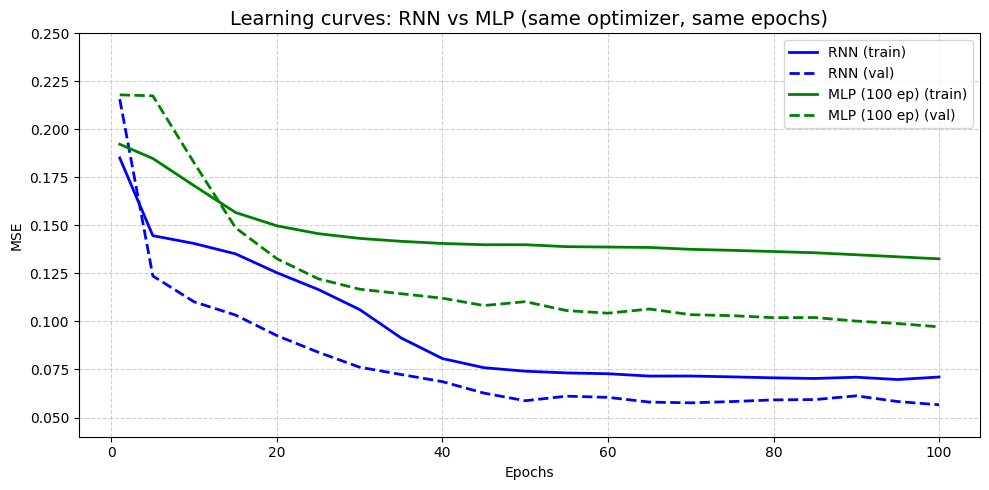

In [16]:
#@title RNN vs MLP: results table and learning curves

rows = []
for name, model in baselines.items():
    if name in ('Persistence', 'Markov-2 table', 'Oracle'):
        r = evaluate(model, test_windows)
        rows.append([name, '-', '-', f"{r['mse']:.4f}", f"{r['mae']:.4f}", f"{r['acc'] * 100:.1f}%"])

for name, rs in runs.items():
    avg = average_runs(rs)
    rows.append([name, avg['params'], f"{avg['train']['mse']:.4f}", f"{avg['test']['mse']:.4f} +/- {avg['test_mse_std']:.4f}",
                 f"{avg['test']['mae']:.4f}", f"{avg['test']['acc'] * 100:.1f}%"])
print_table(['Model', 'Params', 'Train MSE', 'Test MSE', 'Test MAE', 'State accuracy'], rows)

plot_curves({'RNN': runs['Vanilla RNN (100 epochs)'][0]['history'],
             'MLP (100 ep)': runs['MLP (100 epochs)'][0]['history']},
            'Learning curves: RNN vs MLP (same optimizer, same epochs)', ylim=(0.04, 0.25))

### What we see
* **With the same optimizer and the same number of epochs, the RNN wins clearly:** test MSE 0.071 vs 0.118, and 71% vs 47% accuracy. The RNN is already at the oracle's accuracy.
* **But this is mostly a training-speed gap, not a capability gap.** Look at the other rows. An RNN that only receives the last-step signal (like the MLP does) drops to 0.096. And the MLP trained 3 times longer (300 epochs) reaches 0.088, with a large variation between seeds ($\pm$ 0.022). The RNN is better in this table largely because every window gives it **six** training signals instead of one.
* We will see the converged comparison in section 14 (with Adam, 3 seeds): the MLP gets 0.074 and the RNN 0.072, which is a tie within the seed noise. This is what we should have expected: our rules only depend on the last **two** days, and the MLP's window contains six. **The claim "feedforward networks cannot handle this" is not true for a fixed window that is long enough.** What an MLP cannot do is accept a different number of days, or remember something older than its window. Sections 12 and 15 look at those cases.

## 10. Experiment: Different Optimizers

Up to now we only used basic gradient descent. Here we compare four optimizers on the same RNN, same data and same starting weights (same seed):

* **SGD:** $w \leftarrow w - \eta \, g$
* **SGD with momentum:** keeps a running velocity of the gradients, $v \leftarrow \mu v + g$, then $w \leftarrow w - \eta v$. Directions that keep pointing the same way speed up, noisy ones cancel.
* **RMSprop:** divides each step by a running average of the recent gradient size of that weight, so weights with tiny gradients are not left behind. This is interesting for RNNs because their gradients can have very different sizes.
* **Adam:** momentum + RMSprop together with a bias correction for the first steps.

We compare them on four things: convergence speed (epochs until the validation MSE gets within 15% of the oracle's), training stability (how much the validation loss jumps around at the end), the final loss, and sensitivity to the learning rate (we try $\eta \in \{0.001, 0.01, 0.1\}$ for every optimizer).

In [17]:
#@title Optimizer comparison (4 optimizers x 3 learning rates)

optimizer_epochs = 60
optimizer_builders = {
    'SGD': SGD,
    'SGD + momentum': SGDMomentum,
    'RMSprop': RMSprop,
    'Adam': Adam,
}
learning_rates = [0.001, 0.01, 0.1]

oracle_val_mse = evaluate(OracleBaseline(), val_windows)['mse']
threshold = oracle_val_mse * 1.15

optimizer_runs = {}
rows = []
for name, optimizer_class in optimizer_builders.items():
    for lr in learning_rates:
        r = run_experiment(lambda: TrainableRNN(input_features, hidden_nodes, output_features),
                           lambda: optimizer_class(lr), *windows_split, seed=0, epochs=optimizer_epochs, eval_every=3)
        optimizer_runs[(name, lr)] = r
        hist = r['history']

        reached = [e for e, v in zip(hist['epoch'], hist['val_mse']) if v <= threshold]
        speed = reached[0] if reached else 'never'
        tail = hist['val_mse'][len(hist['val_mse']) // 2:]
        jitter = mean_std(tail)[1]

        rows.append([name, lr, f"{r['train']['mse']:.4f}", f"{r['val']['mse']:.4f}", speed, f"{jitter:.4f}"])

print(f"oracle validation MSE: {oracle_val_mse:.4f} | 'converged' means val MSE <= {threshold:.4f}")
print()
print_table(['Optimizer', 'LR', 'Final train MSE', 'Final val MSE', 'Epochs to converge', 'Jitter (std of 2nd half)'], rows)

oracle validation MSE: 0.0569 | 'converged' means val MSE <= 0.0654

Optimizer      | LR    | Final train MSE | Final val MSE | Epochs to converge | Jitter (std of 2nd half)
---------------+-------+-----------------+---------------+--------------------+-------------------------
SGD            | 0.001 | 0.1432          | 0.1160        | never              | 0.0076                  
SGD            | 0.01  | 0.0728          | 0.0605        | 42                 | 0.0061                  
SGD            | 0.1   | 0.0710          | 0.0567        | 6                  | 0.0027                  
SGD + momentum | 0.001 | 0.0729          | 0.0607        | 42                 | 0.0062                  
SGD + momentum | 0.01  | 0.0697          | 0.0578        | 6                  | 0.0011                  
SGD + momentum | 0.1   | 0.3788          | 0.5690        | never              | 0.0000                  
RMSprop        | 0.001 | 0.0786          | 0.0665        | 57                 | 0.0041     

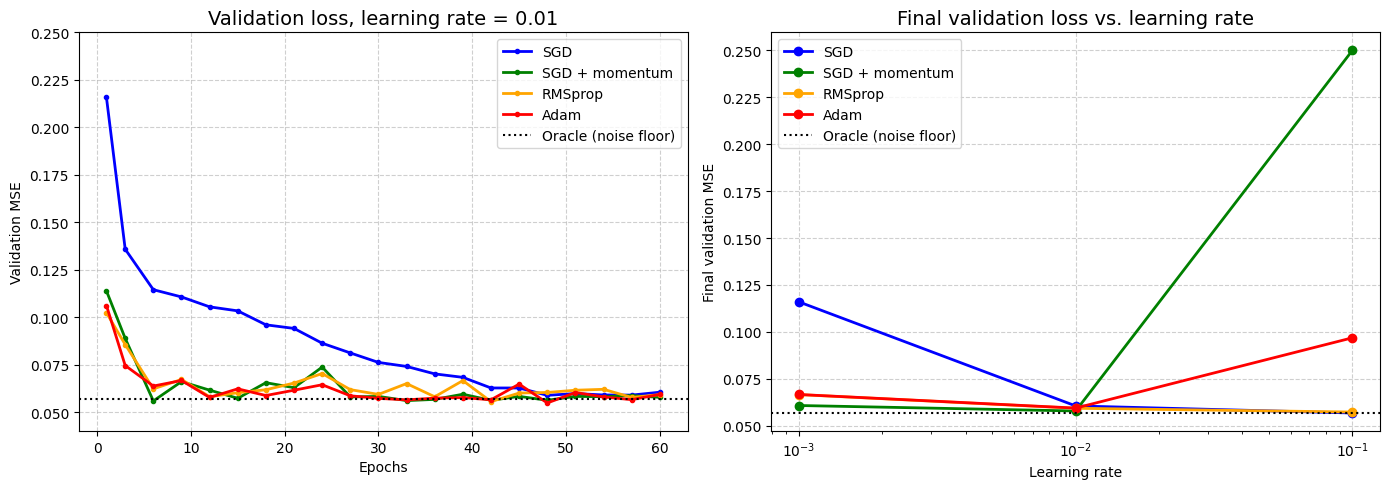

best on validation: SGD with learning rate 0.1 (val MSE 0.0567)


In [18]:
#@title Optimizer comparison: loss curves and learning rate sensitivity

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {'SGD': 'blue', 'SGD + momentum': 'green', 'RMSprop': 'orange', 'Adam': 'red'}

for name in optimizer_builders:
    hist = optimizer_runs[(name, 0.01)]['history']
    axes[0].plot(hist['epoch'], hist['val_mse'], color=colors[name], linewidth=2, marker='o', markersize=3, label=name)
axes[0].axhline(oracle_val_mse, color='black', linestyle=':', label='Oracle (noise floor)')
axes[0].set_title('Validation loss, learning rate = 0.01', fontsize=14)
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Validation MSE')
axes[0].set_ylim(0.04, 0.25)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

for name in optimizer_builders:
    finals = [min(optimizer_runs[(name, lr)]['val']['mse'], 0.25) for lr in learning_rates]
    axes[1].plot(learning_rates, finals, color=colors[name], linewidth=2, marker='o', label=name)
axes[1].axhline(oracle_val_mse, color='black', linestyle=':', label='Oracle (noise floor)')
axes[1].set_xscale('log')
axes[1].set_title('Final validation loss vs. learning rate', fontsize=14)
axes[1].set_xlabel('Learning rate')
axes[1].set_ylabel('Final validation MSE')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

# the best (optimizer, learning rate) on the VALIDATION set. never choose with the test set!
best = min(optimizer_runs, key=lambda k: optimizer_runs[k]['val']['mse'])
print(f"best on validation: {best[0]} with learning rate {best[1]} (val MSE {optimizer_runs[best]['val']['mse']:.4f})")

### What we see
* **Convergence speed:** plain SGD at the learning rate we have been using (0.01) needs about 42 epochs to get within 15% of the oracle. Momentum, RMSprop and Adam at the same learning rate get there in about 6. SGD can also be fast, but it needs a 10x larger learning rate (0.1).
* **Sensitivity to the learning rate** is the biggest difference between them. SGD at 0.001 never converges in 60 epochs. SGD with momentum at 0.1 **diverges** (validation MSE 0.57). Adam at 0.1 is unstable (validation MSE 0.097 and a jitter more than 10x larger than at 0.01). RMSprop is the most forgiving: it ends up within 0.01 of the oracle at all three learning rates, but at 0.1 its loss is noisy. A learning rate of **0.01 works well for all four**.
* **Final loss:** at their good learning rates all four end at about the same place, the noise floor (validation MSE 0.057 to 0.061 against an oracle of 0.057). The differences between those are smaller than what we would get by changing the seed, and each configuration was run once, so we should not rank them.

**Why we use Adam with a learning rate of 0.01 from here on.** The validation set actually picked SGD with learning rate 0.1 (by 0.0003, which is noise). We still chose Adam at 0.01 as the default for the next experiments, and we want to be clear that this is a judgement call and not what the table says: it is among the fastest at a learning rate that did not need any tuning, and the later experiments train very different models (LSTMs, MLPs, RNNs with 32 units) where the best SGD learning rate would probably be different for each of them. Adam rescales every weight's step by its own gradient history, so one learning rate is a safer shared setting.

## 11. Experiment: Different Hidden Layer Sizes

In our first RNN we wrote `hidden_nodes = 8`, but we never asked why 8. Here we try 2, 4, 8, 16 and 32 hidden units and we ask:
* Does a bigger hidden state always give a better score?
* Does it start to overfit (training loss going down while validation loss does not)?
* How much does the training time grow?

Note that the recurrent matrix $W_{hh}$ is $H \times H$, so the number of parameters (and the time) grows with the **square** of the hidden size. From now on we train with **Adam** (learning rate 0.01, 40 epochs). The previous section shows it reaches the plateau in a few epochs without tuning its learning rate (it was not the single best configuration there, see the discussion), and this experiment trains many models. Every size is trained with 2 seeds.

In [19]:
#@title Hidden size sweep

hidden_sizes = [2, 4, 8, 16, 32]
sweep_seeds = [0, 1]

sweep_runs = {}
for H in hidden_sizes:
    sweep_runs[H] = [run_experiment(lambda: TrainableRNN(input_features, H, output_features),
                                    lambda: Adam(adam_lr), *windows_split, seed=s, epochs=adam_epochs)
                     for s in sweep_seeds]
    avg = average_runs(sweep_runs[H])
    log_result('Hidden size (Adam)', f'Vanilla RNN, {H} hidden', avg)
    print(f"hidden = {H:<2} | parameters: {avg['params']:<5} | Train MSE: {avg['train']['mse']:.4f} | Val MSE: {avg['val']['mse']:.4f} | time per run: {avg['seconds']:.1f}s")

hidden = 2  | parameters: 11    | Train MSE: 0.0982 | Val MSE: 0.0768 | time per run: 3.7s
hidden = 4  | parameters: 29    | Train MSE: 0.0726 | Val MSE: 0.0590 | time per run: 6.2s
hidden = 8  | parameters: 89    | Train MSE: 0.0728 | Val MSE: 0.0630 | time per run: 13.6s
hidden = 16 | parameters: 305   | Train MSE: 0.0722 | Val MSE: 0.0583 | time per run: 34.9s
hidden = 32 | parameters: 1121  | Train MSE: 0.0800 | Val MSE: 0.0606 | time per run: 109.9s


hidden = 16 | parameters: 305   | Train MSE: 0.0722 | Val MSE: 0.0583 | time per run: 18.7s


hidden = 32 | parameters: 1121  | Train MSE: 0.0800 | Val MSE: 0.0606 | time per run: 59.1s


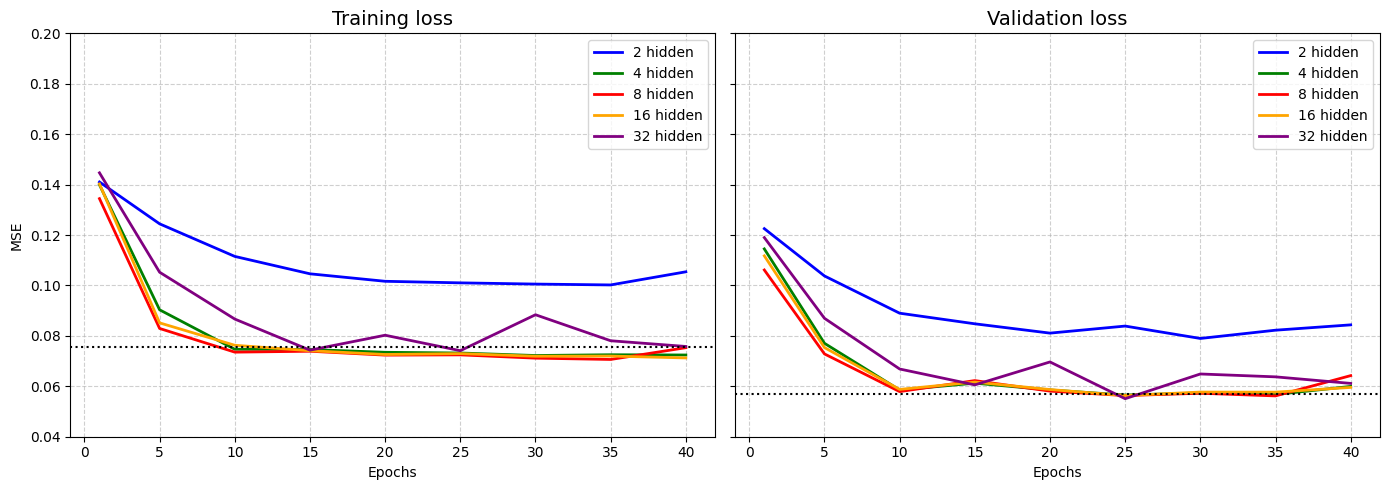

Hidden | Params | Train MSE | Val MSE | Val - Train | Test MSE | Test acc | Time / run
-------+--------+-----------+---------+-------------+----------+----------+-----------
2      | 11     | 0.0982    | 0.0768  | -0.0214     | 0.0916   | 56.0%    | 4s        
4      | 29     | 0.0726    | 0.0590  | -0.0135     | 0.0702   | 71.0%    | 6s        
8      | 89     | 0.0728    | 0.0630  | -0.0098     | 0.0717   | 70.8%    | 14s       
16     | 305    | 0.0722    | 0.0583  | -0.0139     | 0.0711   | 71.2%    | 35s       
32     | 1121   | 0.0800    | 0.0606  | -0.0194     | 0.0733   | 70.7%    | 110s      


In [20]:
#@title Hidden size sweep: curves and table

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
colors = ['blue', 'green', 'red', 'orange', 'purple']
oracle_train_mse = evaluate(OracleBaseline(), train_windows)['mse']

for H, color in zip(hidden_sizes, colors):
    hist = sweep_runs[H][0]['history']
    axes[0].plot(hist['epoch'], hist['train_mse'], color=color, linewidth=2, label=f'{H} hidden')
    axes[1].plot(hist['epoch'], hist['val_mse'], color=color, linewidth=2, label=f'{H} hidden')

for ax, title in zip(axes, ['Training loss', 'Validation loss']):
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Epochs')
    ax.set_ylim(0.04, 0.2)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()
axes[0].axhline(oracle_train_mse, color='black', linestyle=':')
axes[1].axhline(oracle_val_mse, color='black', linestyle=':')
axes[0].set_ylabel('MSE')
plt.tight_layout()
plt.show()

rows = []
for H in hidden_sizes:
    avg = average_runs(sweep_runs[H])
    gap = avg['val']['mse'] - avg['train']['mse']
    rows.append([H, avg['params'], f"{avg['train']['mse']:.4f}", f"{avg['val']['mse']:.4f}", f"{gap:+.4f}",
                 f"{avg['test']['mse']:.4f}", f"{avg['test']['acc'] * 100:.1f}%", f"{avg['seconds']:.0f}s"])
print_table(['Hidden', 'Params', 'Train MSE', 'Val MSE', 'Val - Train', 'Test MSE', 'Test acc', 'Time / run'], rows)

### What we see
* **Too small is the only real problem.** With 2 hidden units the RNN cannot represent the rules: test MSE 0.092 and 56% accuracy. From 4 hidden units on, all sizes end at the same place (test MSE 0.070 to 0.073, 71% accuracy, the oracle's level). **8 was a reasonable choice, but 4 would have done the same with a third of the parameters** (29 vs 89).
* **Does a bigger hidden state help?** Not after 4 units. The 32-unit model is not better; it even ends with a higher training loss (0.080). We did not investigate why, but it is consistent with a bigger model needing more than 40 epochs.
* **Overfitting:** we do not see it. The validation loss is lower than the training loss for every size (negative "Val - Train" column). This is not a sign of a magic model: our 4 validation sequences just happen to be a bit easier (the oracle's own validation MSE is 0.057, lower than on the test set). With only 8 training sequences of simple rules, we would expect overfitting to show up with much longer training or much bigger networks.
* **Does a larger hidden state mean better memory?** Not by itself. The task only needs 2 days, so extra units have nothing more to remember. Section 15.1 repeats the sweep on a task that needs more memory.
* **Training time** grows quickly: 2 s for 2 units, 7 s for 8, 18 s for 16 and 53 s for 32. The recurrent matrix is $H \times H$, so the work grows about with the square of $H$.

## 12. Experiment: Generalization to Longer Sequences

In section 3 we said that an RNN reuses the same weights at every time step, so it can in theory process sequences of **any** length. We trained on windows of 6 days. What happens if we now give it sequences of 20, 50 or 100 days?

**But theoretical support does not guarantee it works.** During training the hidden state always started from zeros and was never run for more than 6 steps. So for a long sequence, the network is asked to work in a regime it has never seen. The MLP is a good contrast: it can only look at 6 days, so for a longer sequence the only thing we can do is slide its window along the sequence.

We test 4 models on fresh sequences of length 7, 20, 50 and 100 (all sequences are new, none was used for training). Length 7 is the case we trained on: a window of 6 days and the day we want to predict.
* **RNN, continuous:** one pass over the full sequence, the hidden state is never reset.
* **RNN, reset every 6 days:** at every day we feed only the last 6 days to the RNN starting from a zero hidden state (exactly how it was trained). If this one is better than the continuous one, the difference comes from the hidden state drifting.
* **MLP:** sliding window of 6 days.
* **Oracle:** the noise floor.

To be fair we only score the predictions from day 6 on, so every model had its full context.

In [21]:
#@title Train the RNN and the MLP for this experiment (Adam)

long_rnn = run_experiment(lambda: TrainableRNN(input_features, hidden_nodes, output_features),
                          lambda: Adam(adam_lr), *windows_split, seed=0, epochs=adam_epochs)['model']
long_mlp = run_experiment(lambda: MLP(context_length, mlp_hidden_nodes),
                          lambda: Adam(adam_lr), *windows_split, seed=0, epochs=100)['model']

class SlidingWindow:
    # feeds a model only the last `context` days at every step (so its hidden state is reset every time)
    def __init__(self, model, context=context_length):
        self.model, self.context = model, context

    def predict_sequence(self, inputs):
        return [self.model.predict_sequence(inputs[max(0, t - self.context + 1) : t + 1])[-1] for t in range(len(inputs))]

def length_test(models, sequences_per_length, seed=123, start=context_length - 1):
    # for every length we generate NEW sequences and measure the squared error at every position
    set_seed(seed)
    errors = {}
    for L, n in sequences_per_length.items():
        seqs = make_dataset(n, L)
        for name, model in models.items():
            errors[(name, L)] = stepwise_errors(model, seqs, seqs)
    return errors

def mean_error(errs, start=context_length - 1, end=None):
    chunk = errs[start:end]
    return sum(chunk) / len(chunk)

length_models = {
    'RNN, continuous': long_rnn,
    'RNN, reset every 6 days': SlidingWindow(long_rnn),
    'MLP (sliding window)': long_mlp,
    'Oracle': OracleBaseline(),
}
sequences_per_length = {7: 400, 20: 100, 50: 60, 100: 40}
length_errors = length_test(length_models, sequences_per_length)

rows = []
for name in length_models:
    rows.append([name] + [f"{mean_error(length_errors[(name, L)]):.4f}" for L in sequences_per_length])
print_table(['Test MSE (day 6 onwards)'] + [f'length {L}' for L in sequences_per_length], rows)

Test MSE (day 6 onwards) | length 7 | length 20 | length 50 | length 100
-------------------------+----------+-----------+-----------+-----------
RNN, continuous          | 0.0898   | 0.0723    | 0.0805    | 0.0795    
RNN, reset every 6 days  | 0.0898   | 0.0725    | 0.0801    | 0.0789    
MLP (sliding window)     | 0.0856   | 0.0728    | 0.0812    | 0.0790    
Oracle                   | 0.0680   | 0.0651    | 0.0719    | 0.0702    


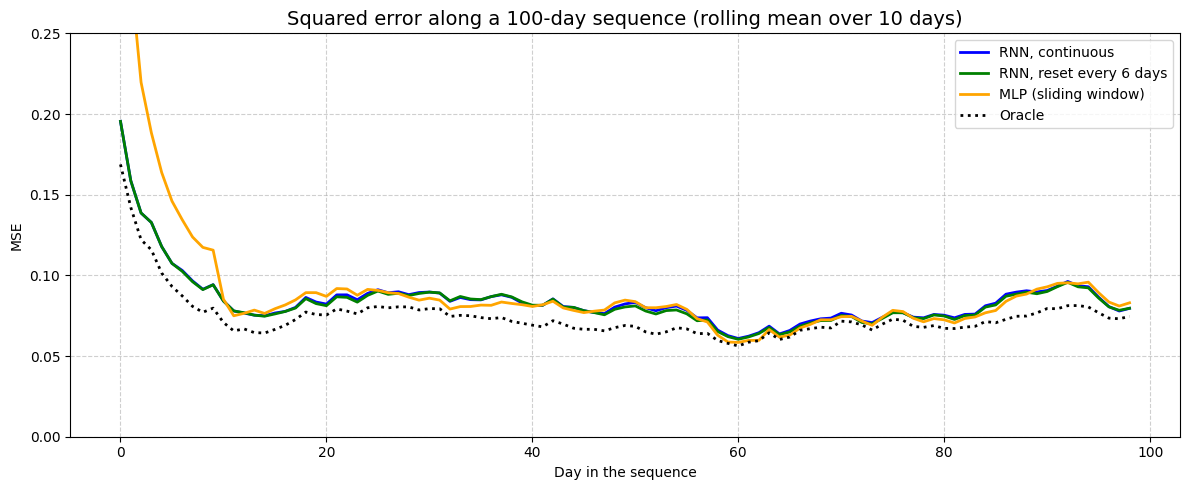

Length-100 sequences, error by position | days 6-20 | days 20-50 | days 50-99
----------------------------------------+-----------+------------+-----------
RNN, continuous                         | 0.0792    | 0.0848     | 0.0763    
RNN, reset every 6 days                 | 0.0785    | 0.0843     | 0.0757    
MLP (sliding window)                    | 0.0820    | 0.0837     | 0.0753    
Oracle                                  | 0.0698    | 0.0726     | 0.0689    


In [22]:
#@title Longer sequences: how does the error evolve along a 100-day sequence?

def rolling_mean(values, window=10):
    return [sum(values[max(0, i - window + 1) : i + 1]) / len(values[max(0, i - window + 1) : i + 1]) for i in range(len(values))]

fig, ax = plt.subplots(1, 1, figsize=(12, 5))
colors = {'RNN, continuous': 'blue', 'RNN, reset every 6 days': 'green', 'MLP (sliding window)': 'orange', 'Oracle': 'black'}
for name in length_models:
    errs = length_errors[(name, 100)]
    ax.plot(range(len(errs)), rolling_mean(errs), color=colors[name], linewidth=2,
            linestyle=':' if name == 'Oracle' else '-', label=name)
ax.set_title('Squared error along a 100-day sequence (rolling mean over 10 days)', fontsize=14)
ax.set_xlabel('Day in the sequence')
ax.set_ylabel('MSE')
ax.set_ylim(0, 0.25)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

rows = []
for name in length_models:
    errs = length_errors[(name, 100)]
    rows.append([name, f"{mean_error(errs, 5, 20):.4f}", f"{mean_error(errs, 20, 50):.4f}", f"{mean_error(errs, 50, 99):.4f}"])
print_table(['Length-100 sequences, error by position', 'days 6-20', 'days 20-50', 'days 50-99'], rows)

### What we see
* **The RNN generalizes to longer sequences without trouble in this environment.** Its error on 20, 50 and 100-day sequences stays around 0.07 to 0.08, which is the same distance (about 0.01) from the oracle as on short sequences, and it does not grow along the 100 days (see the plot and the three position buckets).
* **Continuous vs reset:** the RNN that runs through the whole sequence is as good as the one we restart every 6 days (0.0795 vs 0.0789 at length 100). So the hidden state does **not** drift or blow up over 100 steps, even though it never ran for more than 6 steps during training. The MLP with a sliding window is also the same (0.0790).
* The length-7 column is higher for every model than the longer ones (even the oracle changes between columns, because every column uses different sequences). Since for length 7 we only score one prediction per sequence, early in the sequence, we would not read much into it.
* **The important caveat:** this experiment shows that the hidden state stays stable, **not** that the RNN can remember things for a long time. Our environment only needs 2 days, so there is nothing to forget. "The RNN supports any length" is true; "the RNN can use information from 100 days ago" is a different statement, and the gradient analysis in the next section says it is much harder.

## 13. Gradient Analysis: Vanishing and Exploding Gradients

In section 5 we explained that BPTT multiplies one Jacobian per time step, so the gradient that reaches a day $k$ steps in the past is roughly

$$\frac{\partial h_T}{\partial h_{T-k}} = \prod_{j=T-k+1}^{T} \text{diag}\big(1 - h_j^2\big) \, W_{hh}$$

If the factors are smaller than 1 the product shrinks exponentially (**vanishing**), if they are bigger than 1 it grows exponentially (**exploding**). Now we measure it instead of just writing it.

**How we measure it:** we run BPTT from the loss of the **last** time step only, and at every earlier time step $t$ we compute the size of the gradient $\|\partial L_T / \partial h_t\|$. We divide it by the size at the last step, so the plotted number is simply *"what fraction of the learning signal reaches this day"*. The value 1 means all of it, 0.001 means almost none. We average over 20 random sequences from our stock environment.

We look at four questions:
1. How does the sequence length affect the gradient?
2. How does the initialization of $W_{hh}$ affect it?
3. Does gradient clipping fix vanishing gradients? Does it only address exploding?
4. What happens to training when gradients explode, with and without clipping?

**Why the ratio and not the raw gradient?** The raw size depends on how wrong the prediction is at that moment, and that changes during training. The ratio only depends on the weights and on the data, which is what we want to look at.

In [23]:
#@title Gradient analysis helpers

def gradient_flow(model, inputs):
    # BPTT only from the LAST output. at every step t we measure how big the gradient dL_T / dh_t is,
    # relative to the gradient at the last step. so a value of 0.01 means "only 1% of the learning signal
    # reaches this day". (we use the ratio so it doesn't matter how wrong the prediction was)
    x, h, y = model.forward(inputs)
    T = len(inputs) - 1
    dy = [[sigmoid_deriv(y[T][0][0])]]                 # derivative of the output layer (the loss part is a constant)
    dh = dot(transpose(model.Why), dy)

    norms = [0.0] * len(inputs)
    for t in reversed(range(len(inputs))):
        norms[t] = norm(dh)
        dtanh = [[dh[i][0] * (1.0 - h[t][i][0] ** 2)] for i in range(model.hidden_size)]
        dh = dot(transpose(model.Whh), dtanh)

    return [n / norms[T] for n in norms]                # index = day, last index = 1.0


def average_gradient_flow(model, length, n_sequences=20, flow_fn=gradient_flow):
    # average over several random sequences (as generated by our stock environment), in "steps back from the end"
    total = [0.0] * length
    for _ in range(n_sequences):
        seq = generate_sequence(length, [random.choice(states), random.choice(states)])
        flow = flow_fn(model, seq)
        for t in range(length):
            total[t] += flow[t] / n_sequences
    return list(reversed(total))                        # index k = how many steps we went back from the last step


def orthogonal_matrix(n, gain=1.0):
    # Gram-Schmidt on random vectors: all rows have length 1 and are perpendicular, so multiplying by this
    # matrix rotates a vector without shrinking or growing it
    vectors = []
    for _ in range(n):
        v = [random.gauss(0, 1) for _ in range(n)]
        for u in vectors:
            d = sum(a * b for a, b in zip(v, u))
            v = [a - d * b for a, b in zip(v, u)]
        length = math.sqrt(sum(a * a for a in v))
        vectors.append([a / length for a in v])
    return [[gain * vectors[i][j] for j in range(n)] for i in range(n)]


def make_rnn(hidden_size, whh_init=0.1, seed=0):
    # a fresh RNN where only the recurrent matrix is initialised differently
    # whh_init = float -> uniform in [-whh_init, whh_init] (0.1 is what the first RNN used)
    # whh_init = ('orthogonal', gain) -> orthogonal matrix times gain
    set_seed(seed)
    model = TrainableRNN(input_features, hidden_size, output_features)
    if isinstance(whh_init, tuple):
        model.Whh = orthogonal_matrix(hidden_size, whh_init[1])
    else:
        model.Whh = random_matrix(hidden_size, hidden_size, whh_init)
    return model


def max_abs(M):
    return max(abs(v) for row in M for v in row)

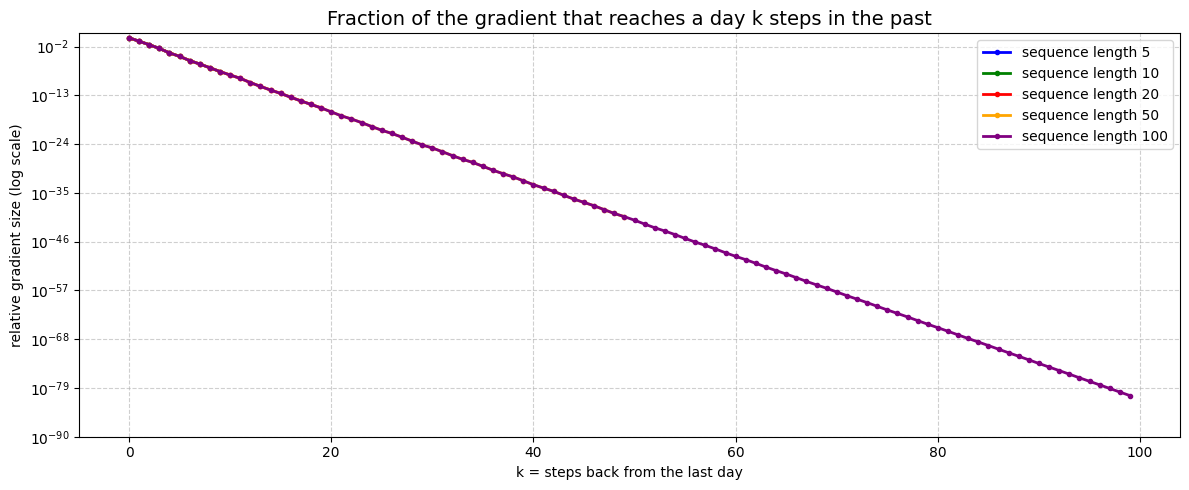

Sequence length | 1 step back | 4 steps back | first day of the sequence
----------------+-------------+--------------+--------------------------
5               | 1.63e-01    | 3.89e-04     | 3.89e-04                 
10              | 1.63e-01    | 3.89e-04     | 2.40e-08                 
20              | 1.63e-01    | 3.89e-04     | 1.52e-16                 
50              | 1.63e-01    | 3.89e-04     | 4.27e-41                 
100             | 1.63e-01    | 3.89e-04     | 1.89e-81                 


In [24]:
#@title 1. Gradient flow for different sequence lengths (the weights of our first RNN: Whh ~ U(-0.1, 0.1))

lengths = [5, 10, 20, 50, 100]
default_rnn = make_rnn(hidden_nodes, 0.1)

fig, ax = plt.subplots(1, 1, figsize=(12, 5))
colors = ['blue', 'green', 'red', 'orange', 'purple']
rows = []
for L, color in zip(lengths, colors):
    set_seed(L)
    flow = average_gradient_flow(default_rnn, L)
    ax.plot(range(L), flow, color=color, linewidth=2, marker='o', markersize=3, label=f'sequence length {L}')
    rows.append([L, f"{flow[1]:.2e}", f"{flow[min(4, L - 1)]:.2e}", f"{flow[L - 1]:.2e}"])

ax.set_yscale('log')
ax.set_title('Fraction of the gradient that reaches a day k steps in the past', fontsize=14)
ax.set_xlabel('k = steps back from the last day')
ax.set_ylabel('relative gradient size (log scale)')
ax.set_ylim(1e-90, 10)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

print_table(['Sequence length', '1 step back', '4 steps back', 'first day of the sequence'], rows)

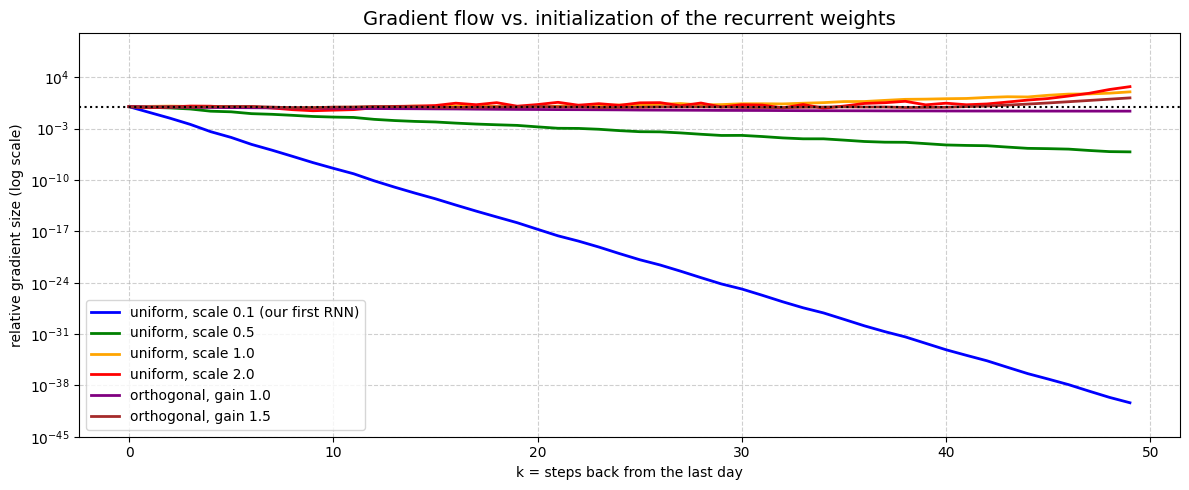

Initialization of Whh              | 10 steps back | 49 steps back | average factor per step
-----------------------------------+---------------+---------------+------------------------
uniform, scale 0.1 (our first RNN) | 3.97e-09      | 4.27e-41      | 0.15                   
uniform, scale 0.5                 | 3.83e-02      | 6.90e-07      | 0.75                   
uniform, scale 1.0                 | 8.12e-01      | 1.05e+02      | 1.10                   
uniform, scale 2.0                 | 3.34e-01      | 5.39e+02      | 1.14                   
orthogonal, gain 1.0               | 6.11e-01      | 2.46e-01      | 0.97                   
orthogonal, gain 1.5               | 8.68e-01      | 1.58e+01      | 1.06                   


In [25]:
#@title 2. Gradient flow for different initializations of Whh (sequence length 50)

inits = [
    (0.1, 'uniform, scale 0.1 (our first RNN)'),
    (0.5, 'uniform, scale 0.5'),
    (1.0, 'uniform, scale 1.0'),
    (2.0, 'uniform, scale 2.0'),
    (('orthogonal', 1.0), 'orthogonal, gain 1.0'),
    (('orthogonal', 1.5), 'orthogonal, gain 1.5'),
]

fig, ax = plt.subplots(1, 1, figsize=(12, 5))
colors = ['blue', 'green', 'orange', 'red', 'purple', 'brown']
rows = []
for (init, label), color in zip(inits, colors):
    model = make_rnn(hidden_nodes, init)
    set_seed(50)
    flow = average_gradient_flow(model, 50)
    ax.plot(range(50), flow, color=color, linewidth=2, label=label)
    # average shrink/growth factor per step, so we can compare with "is it bigger or smaller than 1?"
    per_step = flow[49] ** (1 / 49)
    rows.append([label, f"{flow[10]:.2e}", f"{flow[49]:.2e}", f"{per_step:.2f}"])

ax.axhline(1.0, color='black', linestyle=':')
ax.set_yscale('log')
ax.set_title('Gradient flow vs. initialization of the recurrent weights', fontsize=14)
ax.set_xlabel('k = steps back from the last day')
ax.set_ylabel('relative gradient size (log scale)')
ax.set_ylim(1e-45, 1e10)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

print_table(['Initialization of Whh', '10 steps back', '49 steps back', 'average factor per step'], rows)

In [26]:
#@title 3. Does gradient clipping help? (full BPTT gradient over a 50-day window, every day supervised)

rows = []
for init in [0.1, 0.5, 1.0, 2.0, 3.0]:
    model = make_rnn(hidden_nodes, init)
    set_seed(1)
    seq = generate_sequence(51, [0.0, 0.5])
    loss, grads = model.loss_and_grads(seq[:50], seq[1:51])
    clipped = clip_grads(grads, clip_val)

    total_entries = sum(len(G) * len(G[0]) for G in grads.values())
    n_clipped = sum(1 for G in grads.values() for row in G for v in row if abs(v) > clip_val)
    raw_norm = math.sqrt(sum(norm(G) ** 2 for G in grads.values()))
    clipped_norm = math.sqrt(sum(norm(G) ** 2 for G in clipped.values()))

    set_seed(2)
    signal = average_gradient_flow(model, 50)[49]
    rows.append([init, f"{raw_norm:.3e}", f"{clipped_norm:.3e}", f"{n_clipped}/{total_entries}", f"{signal:.2e}"])

print_table(['Whh scale', 'gradient norm (raw)', 'gradient norm (clipped)', 'entries clipped', 'signal reaching day 1'], rows)

Whh scale | gradient norm (raw) | gradient norm (clipped) | entries clipped | signal reaching day 1
----------+---------------------+-------------------------+-----------------+----------------------
0.1       | 7.352e-01           | 7.352e-01               | 0/89            | 4.28e-41             
0.5       | 7.650e-01           | 7.650e-01               | 0/89            | 7.01e-07             
1.0       | 8.290e+00           | 8.290e+00               | 0/89            | 2.09e+02             
2.0       | 2.421e+01           | 1.311e+01               | 3/89            | 1.89e+00             
3.0       | 2.111e+05           | 4.481e+01               | 79/89           | 4.98e+08             


In [27]:
#@title 4. Training with exploding gradients, with and without clipping (context length 30, Whh scale 3.0)

long_train = make_windows(train_sequences, 30)
long_val = make_windows(val_sequences, 30)

for label, cv in [('with clipping (5.0)', clip_val), ('without clipping', None)]:
    model = make_rnn(hidden_nodes, 3.0, seed=0)
    hist = train(model, SGD(learning_rate), long_train, long_val, epochs=6, clip_value=cv, eval_every=1, seed=0)
    losses = ' -> '.join(f"{v:.3f}" for v in hist['val_mse'])
    print(f"{label:<22} | validation MSE per epoch: {losses}")

with clipping (5.0)    | validation MSE per epoch: 0.213 -> 0.213 -> 0.207 -> 0.220 -> 0.208 -> 0.208
without clipping       | validation MSE per epoch: 0.168 -> 0.139 -> 0.127 -> 0.108 -> 0.093 -> 0.092


### What we see
**1. Sequence length.** The five curves lie exactly on top of each other. The sequence length does not change how fast the gradient shrinks per step; it only decides *how far back the curve goes*. With the initialization we used in the first RNN, the gradient that reaches a day 4 steps back is only 0.04% of the one at the last day, and for a 50-day sequence it is $10^{-41}$. The first RNN worked because the rules only need 1 or 2 days, which are exactly the days where the gradient is still alive.

**2. Initialization.** The average factor per step is the number to look at:
* uniform with scale 0.1 (ours): **0.15** per step $\rightarrow$ vanishing;
* uniform with scale 0.5: 0.75 $\rightarrow$ still vanishing, but slowly ($10^{-7}$ after 49 steps);
* uniform with scale 1.0 or 2.0: 1.10 and 1.14 $\rightarrow$ the gradient **grows** (100x and 500x after 49 steps). It does not explode to astronomically large numbers because when the weights are large the $\tanh$ saturates and its derivative $1-h^2$ goes towards 0, which holds the product back;
* **orthogonal with gain 1.0: 0.97** per step. After 49 steps still 25% of the signal reaches the first day. This is the point of an orthogonal matrix: multiplying by it rotates the vector without shrinking it, so the only shrinking left comes from the $\tanh$ derivative. With a gain of 1.5 it grows again.

So the initialization of $W_{hh}$ decides whether we start in the vanishing, stable or exploding regime, and the "small random numbers" we used in the first RNN put it deep in the vanishing one.

**3. Does clipping fix vanishing gradients? No.** Clipping is applied to the *weight gradients after BPTT is finished*, and it only lowers values that are above the threshold. In the vanishing cases (scale 0.1 and 0.5) **0 of 89 entries are clipped** and the gradient norm is identical before and after, and the signal reaching the first day is still $10^{-41}$ and $10^{-7}$. Clipping cannot create signal that BPTT has already lost. It only addresses the opposite problem: at scale 3.0 the raw gradient norm is 211,000, clipping brings it to 45 (79 of 89 entries were clipped).

**4. A surprise: clipping did not help the exploding case.** We trained with the exploding initialization (scale 3.0) for 6 epochs, once with clipping and once without. We expected clipping to win. The opposite happened: with clipping the validation loss did not improve (0.213 $\rightarrow$ 0.208), and without clipping it went down (0.168 $\rightarrow$ 0.092). This is a single run of a short experiment, and we did **not** isolate the cause. One possible explanation: our clipping is element-wise, and when 79 of 89 entries are above the threshold, all of them become $\pm 5$, so the update ignores the *relative* size of the gradients and moves every weight by the same amount. A clipping on the **norm** of the whole gradient keeps the direction, and we did not test it. What we can say: clipping is a safety net against huge updates, and it is not a substitute for a good initialization and it is not automatically better than no clipping.

## 14. Implementing an LSTM and Comparing it with the Vanilla RNN

The gradient analysis above shows the core problem of the vanilla RNN: the hidden state is **rewritten completely at every step** ($h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b_h)$), so every step the memory goes through a matrix multiplication and a squashing function, and the gradient has to go through them as well.

The **LSTM** (Long Short-Term Memory) fixes this by adding a second state, the **cell state** $c_t$, that works like a conveyor belt: information is only *added* to it or *erased* from it by gates, instead of being rewritten. At every step, with $z_t = [x_t ; h_{t-1}]$ (the input and the previous hidden state stacked together):

$$f_t = \sigma(W_f z_t + b_f) \quad \text{(forget gate: how much of the old memory to keep)}$$
$$i_t = \sigma(W_i z_t + b_i) \quad \text{(input gate: how much of the new candidate to write)}$$
$$g_t = \tanh(W_g z_t + b_g) \quad \text{(candidate memory)}$$
$$o_t = \sigma(W_o z_t + b_o) \quad \text{(output gate: how much of the memory to show)}$$
$$c_t = f_t \odot c_{t-1} + i_t \odot g_t$$
$$h_t = o_t \odot \tanh(c_t)$$
$$y_t = \sigma(W_{hy} h_t + b_y)$$

| Feature | Vanilla RNN | LSTM |
|---|---|---|
| Hidden state | Yes | Yes |
| Cell state | No | Yes |
| Forget gate | No | Yes |
| Input gate | No | Yes |
| Output gate | No | Yes |
| Long-term dependencies | Difficult | Better supported |
| Parameters (8 hidden units) | 89 | 329 |

Decisions in the implementation:
* **Same philosophy as before:** plain Python lists, a `forward` that stores everything needed for backprop, and a `loss_and_grads` that goes backwards through time. The only difference is that we also need to carry a gradient for the cell state, `dc_next`, which flows backwards **only through the forget gate** ($\partial c_t / \partial c_{t-1} = f_t$). That is the whole trick: if the forget gate is close to 1 the gradient passes through almost unchanged.
* **Forget bias initialized to 1:** with a bias of 0 the forget gate starts at $\sigma(0) = 0.5$, which halves the memory at every step. With bias 1 it starts at 0.73 so the cell remembers by default, and it can learn to forget later. This is a standard trick.
* **Gradient check:** an LSTM backward pass has many places to make a mistake, so we verify it numerically before trusting any result. We nudge one weight by $\pm\epsilon$ and compare $(L(w+\epsilon) - L(w-\epsilon)) / 2\epsilon$ with the gradient from our backward pass. They must agree.
* **Fair comparison:** same datasets, same optimizer (Adam), same epochs and same metrics as the RNN. We also train an LSTM with **4** hidden units, which has 101 parameters, close to the RNN's 89, so we can see if the LSTM only wins because it is bigger.

In [28]:
#@title The LSTM from scratch

class LSTM:
    def __init__(self, input_size, hidden_size, output_size):
        self.hidden_size = hidden_size
        self.input_size = input_size
        concat_size = input_size + hidden_size

        # every gate sees the current input AND the previous hidden state stacked together: z_t = [x_t ; h_{t-1}]
        self.Wf = random_matrix(hidden_size, concat_size)  # forget gate
        self.Wi = random_matrix(hidden_size, concat_size)  # input gate
        self.Wo = random_matrix(hidden_size, concat_size)  # output gate
        self.Wg = random_matrix(hidden_size, concat_size)  # candidate memory
        self.Why = random_matrix(output_size, hidden_size)

        # the forget bias starts at 1.0 so that at the beginning the cell REMEMBERS by default (sigmoid(1) = 0.73)
        self.bf = [[1.0] for _ in range(hidden_size)]
        self.bi = zeros(hidden_size, 1)
        self.bo = zeros(hidden_size, 1)
        self.bg = zeros(hidden_size, 1)
        self.by = zeros(output_size, 1)

    def parameters(self):
        return {'Wf': self.Wf, 'Wi': self.Wi, 'Wo': self.Wo, 'Wg': self.Wg, 'Why': self.Why,
                'bf': self.bf, 'bi': self.bi, 'bo': self.bo, 'bg': self.bg, 'by': self.by}

    def forward(self, inputs):
        cache = {'z': {}, 'f': {}, 'i': {}, 'o': {}, 'g': {}, 'c': {}, 'h': {}, 'y': {}}
        cache['h'][-1] = zeros(self.hidden_size, 1)
        cache['c'][-1] = zeros(self.hidden_size, 1)

        for t in range(len(inputs)):
            z = vstack([[inputs[t]]], cache['h'][t - 1])

            f = apply_fn(add(dot(self.Wf, z), self.bf), sigmoid)   # how much of the old memory to keep
            i = apply_fn(add(dot(self.Wi, z), self.bi), sigmoid)   # how much of the new candidate to write
            o = apply_fn(add(dot(self.Wo, z), self.bo), sigmoid)   # how much of the memory to show
            g = apply_fn(add(dot(self.Wg, z), self.bg), tanh)      # the new candidate memory

            # c_t = f * c_{t-1} + i * g    (the cell state is updated by ADDING, not by squashing everything again)
            c = add(hadamard(f, cache['c'][t - 1]), hadamard(i, g))
            # h_t = o * tanh(c_t)
            h = hadamard(o, apply_fn(c, tanh))
            y = apply_fn(add(dot(self.Why, h), self.by), sigmoid)

            for key, val in zip(['z', 'f', 'i', 'o', 'g', 'c', 'h', 'y'], [z, f, i, o, g, c, h, y]):
                cache[key][t] = val
        return cache

    def predict_sequence(self, inputs):
        cache = self.forward(inputs)
        return [cache['y'][t][0][0] for t in range(len(inputs))]

    def loss_and_grads(self, inputs, targets, last_only=False):
        cache = self.forward(inputs)
        H, I = self.hidden_size, self.input_size

        grads = {name: zeros(len(P), len(P[0])) for name, P in self.parameters().items()}
        dh_next = zeros(H, 1)
        dc_next = zeros(H, 1)
        loss = 0.0

        for t in reversed(range(len(targets))):
            y, h, c = cache['y'][t], cache['h'][t], cache['c'][t]
            f, i, o, g, z = cache['f'][t], cache['i'][t], cache['o'][t], cache['g'][t], cache['z'][t]
            c_prev = cache['c'][t - 1]

            weight = 1.0 if (not last_only or t == len(targets) - 1) else 0.0
            loss += weight * (y[0][0] - targets[t]) ** 2
            dy = [[2.0 * weight * (y[0][0] - targets[t]) * sigmoid_deriv(y[0][0])]]
            grads['Why'] = add(grads['Why'], dot(dy, transpose(h)))
            grads['by'] = add(grads['by'], dy)

            dh = add(dot(transpose(self.Why), dy), dh_next)

            tanh_c = apply_fn(c, tanh)
            do = hadamard(dh, tanh_c)
            # the cell state receives gradient from the output of this step AND from the future cell state
            dc = add(hadamard(hadamard(dh, o), apply_fn(tanh_c, lambda v: 1.0 - v ** 2)), dc_next)
            df = hadamard(dc, c_prev)
            di = hadamard(dc, g)
            dg = hadamard(dc, i)

            # back through the gate activations
            do_raw = hadamard(do, apply_fn(o, sigmoid_deriv))
            df_raw = hadamard(df, apply_fn(f, sigmoid_deriv))
            di_raw = hadamard(di, apply_fn(i, sigmoid_deriv))
            dg_raw = hadamard(dg, apply_fn(g, lambda v: 1.0 - v ** 2))

            for gate, d_raw in zip(['f', 'i', 'o', 'g'], [df_raw, di_raw, do_raw, dg_raw]):
                grads['W' + gate] = add(grads['W' + gate], dot(d_raw, transpose(z)))
                grads['b' + gate] = add(grads['b' + gate], d_raw)

            dz = add(add(dot(transpose(self.Wf), df_raw), dot(transpose(self.Wi), di_raw)),
                     add(dot(transpose(self.Wo), do_raw), dot(transpose(self.Wg), dg_raw)))

            dh_next = dz[I:]                  # the hidden-state part of z goes to the previous step
            dc_next = hadamard(dc, f)         # the cell state flows back only through the forget gate

        return loss / (1 if last_only else len(targets)), grads


def gradient_check(model, inputs, targets, n_checks=6, eps=1e-5):
    # compares the analytical gradient with a numerical one: (L(w + eps) - L(w - eps)) / (2 * eps)
    # if the backward pass is right, the two numbers should agree to many decimals
    _, grads = model.loss_and_grads(inputs, targets)
    params = model.parameters()
    worst = 0.0
    picker = random.Random(0)
    for _ in range(n_checks):
        name = picker.choice(list(params))
        i = picker.randrange(len(params[name]))
        j = picker.randrange(len(params[name][0]))
        original = params[name][i][j]

        params[name][i][j] = original + eps
        loss_plus, _ = model.loss_and_grads(inputs, targets)
        params[name][i][j] = original - eps
        loss_minus, _ = model.loss_and_grads(inputs, targets)
        params[name][i][j] = original

        # our losses are averaged over the time steps while the gradients are summed, so we rescale
        numerical = (loss_plus - loss_minus) / (2 * eps) * len(targets)
        analytical = grads[name][i][j]
        rel = abs(numerical - analytical) / max(1e-8, abs(numerical) + abs(analytical))
        worst = max(worst, rel)
        print(f"{name}[{i}][{j}] | analytical: {analytical:+.8f} | numerical: {numerical:+.8f}")
    print(f"worst relative difference: {worst:.2e}")
    return worst

In [29]:
#@title Gradient check: our backward passes against numerical gradients

set_seed(0)
print("LSTM (4 hidden units):")
gradient_check(LSTM(1, 4, 1), example_inputs, example_targets)
print()
print("Vanilla RNN (4 hidden units):")
gradient_check(TrainableRNN(1, 4, 1), example_inputs, example_targets)

LSTM (4 hidden units):
bi[3][0] | analytical: +0.00010911 | numerical: +0.00010911
Why[0][3] | analytical: -0.00810622 | numerical: -0.00810622
Why[0][2] | analytical: -0.00669670 | numerical: -0.00669670
by[0][0] | analytical: +0.00117811 | numerical: +0.00117811
Why[0][0] | analytical: +0.00589537 | numerical: +0.00589537
by[0][0] | analytical: +0.00117811 | numerical: +0.00117811
worst relative difference: 1.50e-08

Vanilla RNN (4 hidden units):
bh[3][0] | analytical: -0.00038281 | numerical: -0.00038281
Why[0][3] | analytical: -0.01766331 | numerical: -0.01766331
Why[0][2] | analytical: -0.01378103 | numerical: -0.01378103
by[0][0] | analytical: -0.00008813 | numerical: -0.00008813
Why[0][0] | analytical: -0.00715518 | numerical: -0.00715518
by[0][0] | analytical: -0.00008813 | numerical: -0.00008813
worst relative difference: 4.90e-08


4.898614936027551e-08

In [30]:
#@title Training: Vanilla RNN vs LSTM vs MLP (Adam, 3 seeds)

lstm_configs = {
    'Vanilla RNN (8 hidden)': (lambda: TrainableRNN(input_features, hidden_nodes, output_features), adam_epochs),
    'LSTM (8 hidden)':        (lambda: LSTM(input_features, hidden_nodes, output_features), adam_epochs),
    'LSTM (4 hidden)':        (lambda: LSTM(input_features, 4, output_features), adam_epochs),
    'MLP (11 hidden)':        (lambda: MLP(context_length, mlp_hidden_nodes), 100),
}

lstm_runs = {}
for name, (builder, epochs) in lstm_configs.items():
    lstm_runs[name] = [run_experiment(builder, lambda: Adam(adam_lr), *windows_split, seed=s, epochs=epochs) for s in seeds]
    avg = average_runs(lstm_runs[name])
    log_result('RNN vs LSTM vs MLP (Adam)', name, avg)
    print(f"{name:<24} | Test MSE: {avg['test']['mse']:.4f} +/- {avg['test_mse_std']:.4f} | time per run: {avg['seconds']:.0f}s")

# we keep the first seed of each model: later sections reuse them as the models trained on the clean data
clean_models = {
    'Vanilla RNN': lstm_runs['Vanilla RNN (8 hidden)'][0]['model'],
    'LSTM': lstm_runs['LSTM (8 hidden)'][0]['model'],
    'MLP': lstm_runs['MLP (11 hidden)'][0]['model'],
}

Vanilla RNN (8 hidden)   | Test MSE: 0.0719 +/- 0.0027 | time per run: 13s
LSTM (8 hidden)          | Test MSE: 0.0725 +/- 0.0015 | time per run: 49s
LSTM (4 hidden)          | Test MSE: 0.0720 +/- 0.0015 | time per run: 22s
MLP (11 hidden)          | Test MSE: 0.0742 +/- 0.0007 | time per run: 9s


MLP (11 hidden)          | Test MSE: 0.0742 +/- 0.0007 | time per run: 5s


Model                  | Params | Train MSE | Test MSE          | Test MAE | State accuracy | Time / run
-----------------------+--------+-----------+-------------------+----------+----------------+-----------
Persistence            | -      | -         | 0.1806            | 0.2784   | 52.6%          | -         
Markov-2 table         | -      | -         | 0.0680            | 0.1858   | 71.0%          | -         
Oracle                 | -      | -         | 0.0673            | 0.1767   | 71.0%          | -         
Vanilla RNN (8 hidden) | 89     | 0.0720    | 0.0719 +/- 0.0027 | 0.1972   | 71.0%          | 13s       
LSTM (8 hidden)        | 329    | 0.0675    | 0.0725 +/- 0.0015 | 0.1972   | 71.0%          | 49s       
LSTM (4 hidden)        | 101    | 0.0704    | 0.0720 +/- 0.0015 | 0.1989   | 71.0%          | 22s       
MLP (11 hidden)        | 89     | 0.0676    | 0.0742 +/- 0.0007 | 0.1921   | 70.9%          | 9s        


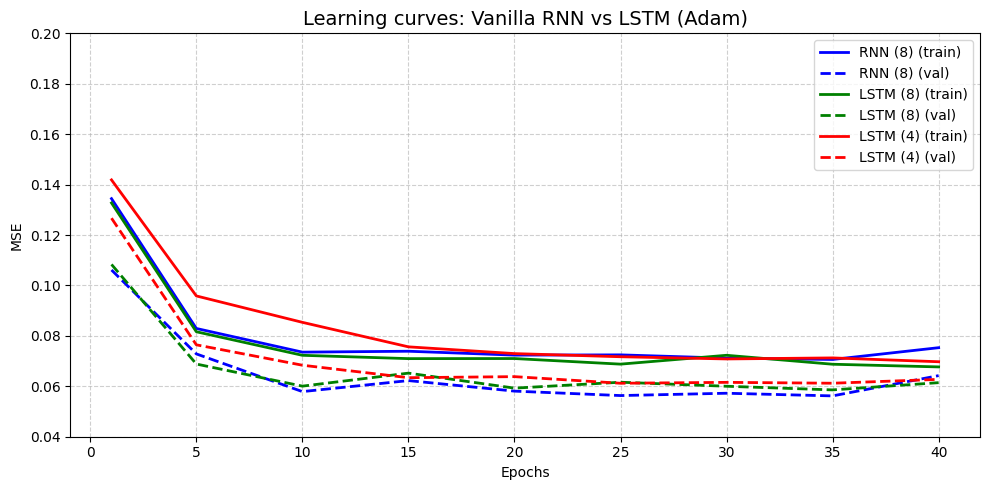

In [31]:
#@title Vanilla RNN vs LSTM vs MLP: results

rows = []
for name in ['Persistence', 'Markov-2 table', 'Oracle']:
    r = evaluate(baselines[name], test_windows)
    rows.append([name, '-', '-', f"{r['mse']:.4f}", f"{r['mae']:.4f}", f"{r['acc'] * 100:.1f}%", '-'])
for name, rs in lstm_runs.items():
    avg = average_runs(rs)
    rows.append([name, avg['params'], f"{avg['train']['mse']:.4f}", f"{avg['test']['mse']:.4f} +/- {avg['test_mse_std']:.4f}",
                 f"{avg['test']['mae']:.4f}", f"{avg['test']['acc'] * 100:.1f}%", f"{avg['seconds']:.0f}s"])
print_table(['Model', 'Params', 'Train MSE', 'Test MSE', 'Test MAE', 'State accuracy', 'Time / run'], rows)

plot_curves({'RNN (8)': lstm_runs['Vanilla RNN (8 hidden)'][0]['history'],
             'LSTM (8)': lstm_runs['LSTM (8 hidden)'][0]['history'],
             'LSTM (4)': lstm_runs['LSTM (4 hidden)'][0]['history']},
            'Learning curves: Vanilla RNN vs LSTM (Adam)', ylim=(0.04, 0.2))

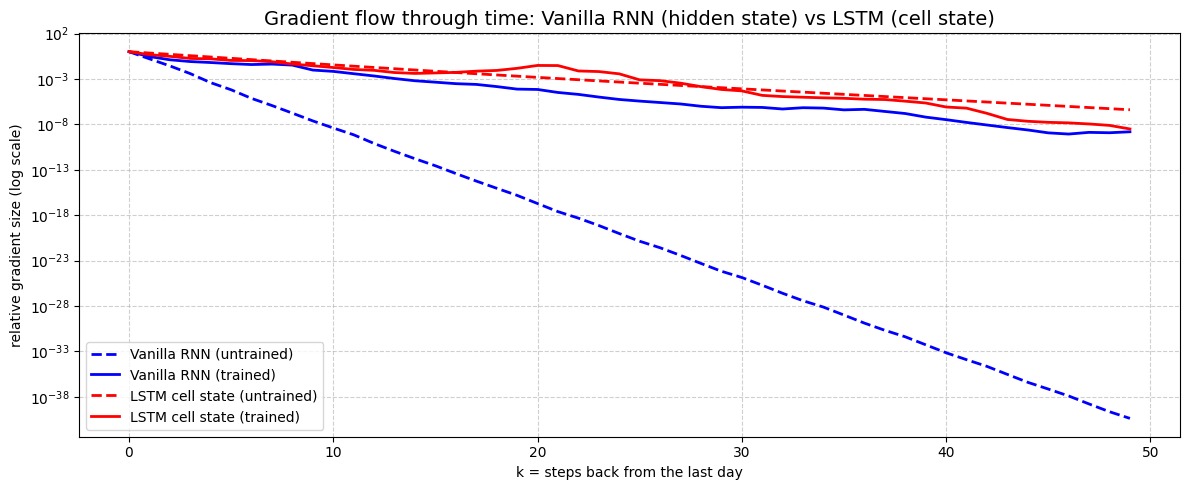

Model                       | 10 steps back | 49 steps back
----------------------------+---------------+--------------
Vanilla RNN (untrained)     | 3.97e-09      | 4.27e-41     
Vanilla RNN (trained)       | 6.76e-03      | 1.52e-09     
LSTM cell state (untrained) | 3.51e-02      | 4.03e-07     
LSTM cell state (trained)   | 1.80e-02      | 3.10e-09     


In [32]:
#@title Gradient flow: Vanilla RNN vs LSTM (untrained and trained)

def lstm_gradient_flow(model, inputs):
    # same idea as gradient_flow, but we follow the gradient through the CELL state c_t
    # (the memory conveyor belt of the LSTM) instead of the hidden state
    cache = model.forward(inputs)
    T = len(inputs) - 1
    H, I = model.hidden_size, model.input_size

    y = cache['y'][T]
    dh = dot(transpose(model.Why), [[sigmoid_deriv(y[0][0])]])
    dc_next = zeros(H, 1)

    norms = [0.0] * len(inputs)
    for t in reversed(range(len(inputs))):
        c, f, i, o, g, z = cache['c'][t], cache['f'][t], cache['i'][t], cache['o'][t], cache['g'][t], cache['z'][t]
        tanh_c = apply_fn(c, tanh)

        dc = add(hadamard(hadamard(dh, o), apply_fn(tanh_c, lambda v: 1.0 - v ** 2)), dc_next)
        norms[t] = norm(dc)

        df_raw = hadamard(hadamard(dc, cache['c'][t - 1]), apply_fn(f, sigmoid_deriv))
        di_raw = hadamard(hadamard(dc, g), apply_fn(i, sigmoid_deriv))
        dg_raw = hadamard(hadamard(dc, i), apply_fn(g, lambda v: 1.0 - v ** 2))
        do_raw = hadamard(hadamard(dh, tanh_c), apply_fn(o, sigmoid_deriv))

        dz = add(add(dot(transpose(model.Wf), df_raw), dot(transpose(model.Wi), di_raw)),
                 add(dot(transpose(model.Wo), do_raw), dot(transpose(model.Wg), dg_raw)))
        dh = dz[I:]
        dc_next = hadamard(dc, f)

    return [n / norms[T] for n in norms]

set_seed(0)
fresh_lstm = LSTM(input_features, hidden_nodes, output_features)
flow_models = [
    ('Vanilla RNN (untrained)', make_rnn(hidden_nodes, 0.1), gradient_flow, 'blue', '--'),
    ('Vanilla RNN (trained)', clean_models['Vanilla RNN'], gradient_flow, 'blue', '-'),
    ('LSTM cell state (untrained)', fresh_lstm, lstm_gradient_flow, 'red', '--'),
    ('LSTM cell state (trained)', clean_models['LSTM'], lstm_gradient_flow, 'red', '-'),
]

fig, ax = plt.subplots(1, 1, figsize=(12, 5))
rows = []
for label, model, fn, color, style in flow_models:
    set_seed(50)
    flow = average_gradient_flow(model, 50, flow_fn=fn)
    ax.plot(range(50), flow, color=color, linestyle=style, linewidth=2, label=label)
    rows.append([label, f"{flow[10]:.2e}", f"{flow[49]:.2e}"])
ax.set_yscale('log')
ax.set_title('Gradient flow through time: Vanilla RNN (hidden state) vs LSTM (cell state)', fontsize=14)
ax.set_xlabel('k = steps back from the last day')
ax.set_ylabel('relative gradient size (log scale)')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

print_table(['Model', '10 steps back', '49 steps back'], rows)

In [33]:
#@title The LSTM on longer sequences

length_models_lstm = dict(length_models)
length_models_lstm['LSTM'] = clean_models['LSTM']
length_errors_lstm = length_test(length_models_lstm, sequences_per_length)

rows = []
for name in length_models_lstm:
    rows.append([name] + [f"{mean_error(length_errors_lstm[(name, L)]):.4f}" for L in sequences_per_length])
print_table(['Test MSE (day 6 onwards)'] + [f'length {L}' for L in sequences_per_length], rows)

Test MSE (day 6 onwards) | length 7 | length 20 | length 50 | length 100
-------------------------+----------+-----------+-----------+-----------
RNN, continuous          | 0.0898   | 0.0723    | 0.0805    | 0.0795    
RNN, reset every 6 days  | 0.0898   | 0.0725    | 0.0801    | 0.0789    
MLP (sliding window)     | 0.0856   | 0.0728    | 0.0812    | 0.0790    
Oracle                   | 0.0680   | 0.0651    | 0.0719    | 0.0702    
LSTM                     | 0.0816   | 0.0715    | 0.0796    | 0.0754    


### What we see
* **The gradient check passes** (worst relative difference $10^{-8}$), so we can trust the LSTM backward pass.
* **On the stock environment the LSTM does not win.** Test MSE: Vanilla RNN 0.0719, LSTM(8) 0.0725, LSTM(4) 0.0720, MLP 0.0742, with seed variations of 0.002 or so, and all four have the same 71% accuracy. The LSTM costs **3.7x** the parameters and about **3.7x** the training time (26 s vs 7 s). This is what we expect: the LSTM is designed for long dependencies, and this environment does not have them. The LSTM with 4 hidden units (101 parameters, close to the RNN's 89) does as well as the one with 8, so there is no benefit from size either.
* **The gradient flow is where the LSTM is different.** At initialization the cell-state gradient 10 steps back is 0.035 of the last one, against $4 \times 10^{-9}$ for the vanilla RNN's hidden state, which is about 7 orders of magnitude more. (Careful: we compare the cell state of one model with the hidden state of the other, because those are the "memory carriers" of each, so this is not an exact like-for-like comparison.) But the LSTM **does not remove the decay**: its forget gate is below 1, so the gradient still shrinks (about $10^{-7}$ after 49 steps at initialization, $3 \times 10^{-9}$ after training). It slows the vanishing, it does not stop it. It is also interesting that *training* made the vanilla RNN's flow better than its initialization (from $4 \times 10^{-9}$ to $7 \times 10^{-3}$ at 10 steps).
* **Longer sequences:** at 100 days the LSTM is slightly lower (0.0754 vs 0.0795 for the RNN), but it is a single trained model each, so we will not read much into it.
* **What we did not show:** that an LSTM beats a vanilla RNN. For that we need a task with a longer dependency than this environment has. We tried a recall task (output the first value after N steps) while preparing this notebook, but under our settings it was too unstable to give a clean conclusion (the RNN learned and then diverged, and the LSTM was slow to start), so we do not report it as evidence in either direction.

## 15. More Sequential Patterns

Our synthetic market has only one kind of pattern, four simple rules that only need the last two days. A single easy dataset can hide the strengths and weaknesses of an architecture, so we build four new environments, each one asking a different question:

| Dataset | What changes | Question |
|---|---|---|
| **Periodic** | A repeating cycle of 8 days, no randomness | Can the model learn a pattern that needs **more than 2 days** of memory? |
| **Noisy** | Gaussian noise added to the prices we *observe* | How robust is the model to noise? |
| **Anomalies** | Rare spikes and drops far outside the normal range | How fast does the hidden state **recover** from a shock? |
| **Changing regimes** | The rules flip in the middle of the sequence | Can a model with fixed weights adapt to new rules? |

Decisions behind the datasets:
* **Noise and anomalies are added to the observation only, not inside the generator.** The generator compares prices with `==` (for example `yesterday == 0.0`), so noise inside it would break the rules. It is also more realistic: the market has a true state, and we see it through a noisy sensor. The *target* is always the clean true state.
* **For these two datasets we reuse the models trained on the clean data** (section 14). The question is robustness: what happens to a model when the data in production is dirtier than the data it was trained on? For noise we also train a model *on* noisy data, to see if that helps.
* **The periodic cycle was chosen to be ambiguous with 2 days:** the cycle is `0.0, 0.5, 1.0, 1.0, 1.0, 0.5, 0.0, 0.0`, so after `(1.0, 1.0)` the next value is `1.0` the first time and `0.5` the second time. The model has to count. The Markov-2 baseline cannot do this, so it tells us how much the model uses more than 2 days.
* **The regime B rules are the opposite of regime A:** the floor breaks upwards, the surge fizzles out (0.0 $\rightarrow$ 0.5 is followed by 0.0), the crash rebounds and the ceiling breaks downwards. The switch happens at day 32 of every sequence of 64 days.

We use the same three models, the same optimizer and the same metrics as before.

In [34]:
#@title More sequential patterns: periodic, anomalies, noise and changing regimes

def rule_step(yesterday, today, regime='A'):
    # the same transition rules as generate_sequence (regime A), written as a single step so we can reuse them.
    # regime B is a "contrarian market": the four rules are flipped
    if regime == 'A':
        if yesterday == 0.0 and today == 0.0:
            return 0.0 if random.random() < 0.8 else 0.5
        elif yesterday == 0.0 and today == 0.5:
            return 1.0
        elif yesterday == 1.0 and today == 0.5:
            return 0.0
        elif yesterday == 1.0 and today == 1.0:
            return 1.0 if random.random() < 0.8 else 0.5
        return random.choice(states)
    else:
        if yesterday == 0.0 and today == 0.0:      # the floor breaks upwards
            return 1.0 if random.random() < 0.8 else 0.5
        elif yesterday == 0.0 and today == 0.5:    # the surge fizzles out
            return 0.0
        elif yesterday == 1.0 and today == 0.5:    # the crash rebounds
            return 1.0
        elif yesterday == 1.0 and today == 1.0:    # the ceiling breaks downwards
            return 0.0 if random.random() < 0.8 else 0.5
        return random.choice(states)


def generate_regime_sequence(length, initial_sequence, switch_at):
    # regime A until day `switch_at`, regime B afterwards
    sequence = list(initial_sequence)
    while len(sequence) < length:
        regime = 'A' if len(sequence) < switch_at else 'B'
        sequence.append(rule_step(sequence[-2], sequence[-1], regime))
    return sequence


# sanity check: our rule_step must reproduce the original generator exactly when the random seed is the same
set_seed(7)
original_seq = generate_sequence(50, [0.0, 0.5])
set_seed(7)
rebuilt_seq = [0.0, 0.5]
while len(rebuilt_seq) < 50:
    rebuilt_seq.append(rule_step(rebuilt_seq[-2], rebuilt_seq[-1], 'A'))
print(f"rule_step reproduces generate_sequence: {original_seq == rebuilt_seq}")


periodic_cycle = [0.0, 0.5, 1.0, 1.0, 1.0, 0.5, 0.0, 0.0]   # period 8

def generate_periodic(length, phase):
    # a repeating cycle. with only 2 days of history the pattern is ambiguous: (1.0, 1.0) is followed by 1.0
    # the first time and by 0.5 the second time. the model has to count, so it needs a longer memory
    return [periodic_cycle[(phase + i) % len(periodic_cycle)] for i in range(length)]

def add_noise(sequence, sigma):
    # NOISE is added to what we OBSERVE, the underlying state (what we want to predict) stays clean.
    # (we can't add it inside the generator because the rules compare prices with ==)
    return [v + random.gauss(0, sigma) for v in sequence]

def add_anomalies(sequence, probability):
    # sudden spikes (+) and drops (-) far outside the normal 0..1 range, again only in what we observe
    observed, positions = [], []
    for i, v in enumerate(sequence):
        if random.random() < probability:
            observed.append(2.0 if random.random() < 0.5 else -1.0)
            positions.append(i)
        else:
            observed.append(v)
    return observed, positions

rule_step reproduces generate_sequence: True


In [35]:
#@title A helper that trains the three architectures on one dataset (Adam)

model_zoo = {
    'Vanilla RNN': (lambda: TrainableRNN(input_features, hidden_nodes, output_features), adam_epochs),
    'LSTM':        (lambda: LSTM(input_features, hidden_nodes, output_features), adam_epochs),
    'MLP':         (lambda: MLP(context_length, mlp_hidden_nodes), 100),
}

def compare_models(experiment, windows, seed=0):
    runs = {}
    for name, (builder, epochs) in model_zoo.items():
        runs[name] = run_experiment(builder, lambda: Adam(adam_lr), *windows, seed=seed, epochs=epochs)
        log_result(experiment, name, runs[name])
    return runs

### 15.1 Periodic patterns

In [36]:
#@title Periodic dataset: train the three models

def make_periodic_dataset(n, length):
    return [generate_periodic(length, random.randrange(len(periodic_cycle))) for _ in range(n)]

set_seed(11)
periodic_train = make_periodic_dataset(n_train_sequences, sequence_length)
periodic_val = make_periodic_dataset(n_val_sequences, sequence_length)
periodic_test = make_periodic_dataset(n_test_sequences, sequence_length)
periodic_windows = tuple(make_windows(s, context_length) for s in (periodic_train, periodic_val, periodic_test))

periodic_runs = compare_models('Periodic pattern', periodic_windows)

rows = []
for name, model in [('Persistence', PersistenceBaseline()), ('Markov-2 table', Markov2Baseline(periodic_train))]:
    r = evaluate(model, periodic_windows[2])
    rows.append([name, f"{r['mse']:.4f}", f"{r['mae']:.4f}", f"{r['acc'] * 100:.1f}%"])
for name, r in periodic_runs.items():
    rows.append([name, f"{r['test']['mse']:.4f}", f"{r['test']['mae']:.4f}", f"{r['test']['acc'] * 100:.1f}%"])
rows.append(['Perfect (cycle is deterministic)', '0.0000', '0.0000', '100.0%'])
print_table(['Model', 'Test MSE', 'Test MAE', 'State accuracy'], rows)

Model                            | Test MSE | Test MAE | State accuracy
---------------------------------+----------+----------+---------------
Persistence                      | 0.1259   | 0.2517   | 49.7%         
Markov-2 table                   | 0.0310   | 0.1241   | 75.3%         
Vanilla RNN                      | 0.0001   | 0.0059   | 100.0%        
LSTM                             | 0.0001   | 0.0072   | 100.0%        
MLP                              | 0.0001   | 0.0077   | 100.0%        
Perfect (cycle is deterministic) | 0.0000   | 0.0000   | 100.0%        


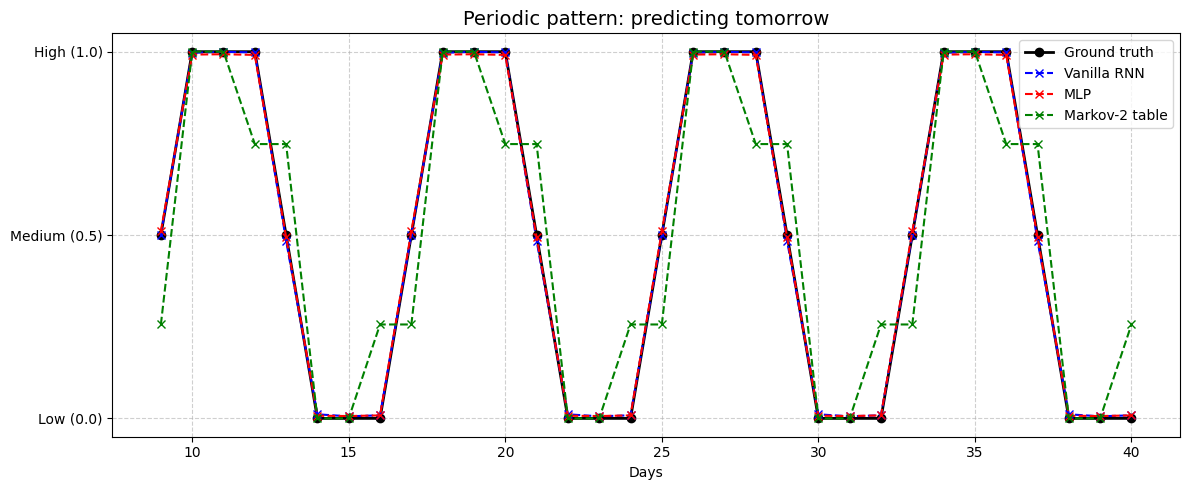

In [37]:
#@title Periodic dataset: what does the prediction look like?

plot_predictions({'Vanilla RNN': periodic_runs['Vanilla RNN']['model'], 'MLP': periodic_runs['MLP']['model'],
                  'Markov-2 table': Markov2Baseline(periodic_train)},
                 periodic_test[0], 'Periodic pattern: predicting tomorrow', start=8, end=40)

In [38]:
#@title Periodic dataset: does a bigger hidden state mean more memory?

rows = []
for H in [2, 4, 8, 16]:
    r = run_experiment(lambda: TrainableRNN(input_features, H, output_features),
                       lambda: Adam(adam_lr), *periodic_windows, seed=0, epochs=adam_epochs)
    log_result('Periodic pattern, hidden size', f'Vanilla RNN, {H} hidden', r)
    rows.append([H, r['params'], f"{r['test']['mse']:.4f}", f"{r['test']['acc'] * 100:.1f}%"])
print_table(['Hidden units', 'Params', 'Test MSE (periodic)', 'State accuracy'], rows)

Hidden units | Params | Test MSE (periodic) | State accuracy
-------------+--------+---------------------+---------------
2            | 11     | 0.0005              | 100.0%        
4            | 29     | 0.0002              | 100.0%        
8            | 89     | 0.0001              | 100.0%        
16           | 305    | 0.0002              | 100.0%        


### 15.2 Noisy sequences

We add Gaussian noise with standard deviation $\sigma$ to every price the model *sees*. $\sigma = 0.1$ is already visible on the plot, and at $\sigma = 0.3$ the noise is bigger than half the gap between two states (0.25), so the state is sometimes ambiguous. We evaluate the models that were trained on **clean** data, and also an RNN and an MLP trained on data with $\sigma = 0.2$.

In [39]:
#@title Noisy dataset: robustness of the clean-trained models + models trained with noise

def noisy_windows(sequences, sigma, seed):
    set_seed(seed)
    observed = [add_noise(s, sigma) for s in sequences]
    return make_windows(observed, context_length, truths=sequences)     # inputs are noisy, targets stay clean

train_sigma = 0.2
noisy_split = (noisy_windows(train_sequences, train_sigma, 41), noisy_windows(val_sequences, train_sigma, 42), test_windows)
noise_trained = {
    'Vanilla RNN (trained with noise)': run_experiment(model_zoo['Vanilla RNN'][0], lambda: Adam(adam_lr), *noisy_split, seed=0, epochs=adam_epochs)['model'],
    'MLP (trained with noise)': run_experiment(model_zoo['MLP'][0], lambda: Adam(adam_lr), *noisy_split, seed=0, epochs=100)['model'],
}

noise_models = {
    'Vanilla RNN': clean_models['Vanilla RNN'],
    'LSTM': clean_models['LSTM'],
    'MLP': clean_models['MLP'],
    'Vanilla RNN (trained with noise)': noise_trained['Vanilla RNN (trained with noise)'],
    'MLP (trained with noise)': noise_trained['MLP (trained with noise)'],
    'Markov-2 table': baselines['Markov-2 table'],
    'Persistence': baselines['Persistence'],
}
sigmas = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]

noise_scores = {name: [] for name in noise_models}
for sigma in sigmas:
    windows = noisy_windows(test_sequences, sigma, 43)
    for name, model in noise_models.items():
        noise_scores[name].append(evaluate(model, windows))

rows = [[name] + [f"{r['mse']:.4f}" for r in noise_scores[name]] for name in noise_models]
print_table(['Test MSE vs. noise level'] + [f'sigma {s}' for s in sigmas], rows)
print()
rows = [[name] + [f"{r['acc'] * 100:.0f}%" for r in noise_scores[name]] for name in noise_models]
print_table(['State accuracy vs. noise level'] + [f'sigma {s}' for s in sigmas], rows)

Test MSE vs. noise level         | sigma 0.0 | sigma 0.05 | sigma 0.1 | sigma 0.2 | sigma 0.3 | sigma 0.5
---------------------------------+-----------+------------+-----------+-----------+-----------+----------
Vanilla RNN                      | 0.0751    | 0.0766     | 0.0869    | 0.1536    | 0.2126    | 0.2508   
LSTM                             | 0.0736    | 0.0743     | 0.0857    | 0.1641    | 0.2200    | 0.2703   
MLP                              | 0.0747    | 0.0758     | 0.0981    | 0.1734    | 0.2334    | 0.2810   
Vanilla RNN (trained with noise) | 0.0743    | 0.0771     | 0.0858    | 0.1242    | 0.1683    | 0.2100   
MLP (trained with noise)         | 0.0941    | 0.0954     | 0.1065    | 0.1544    | 0.2007    | 0.2338   
Markov-2 table                   | 0.0680    | 0.0680     | 0.0685    | 0.1616    | 0.2171    | 0.2541   
Persistence                      | 0.1806    | 0.1845     | 0.1934    | 0.2266    | 0.2801    | 0.4482   

State accuracy vs. noise level   | sigma 0.0 

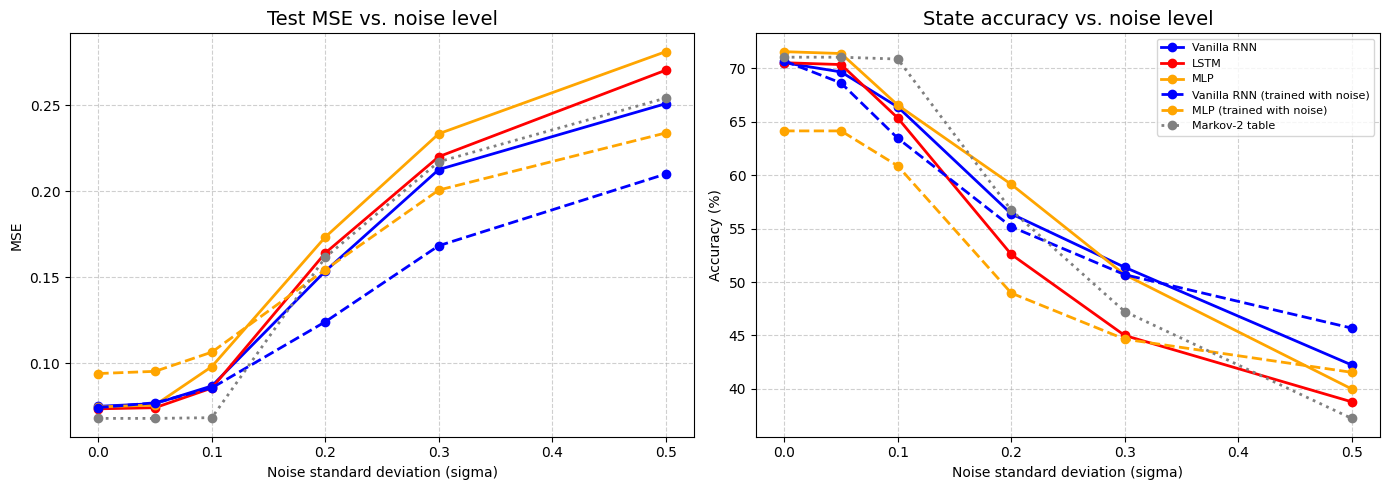

In [40]:
#@title Noisy dataset: plots

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
styles = {'Vanilla RNN': ('blue', '-'), 'LSTM': ('red', '-'), 'MLP': ('orange', '-'),
          'Vanilla RNN (trained with noise)': ('blue', '--'), 'MLP (trained with noise)': ('orange', '--'),
          'Markov-2 table': ('gray', ':')}
for name, (color, style) in styles.items():
    axes[0].plot(sigmas, [r['mse'] for r in noise_scores[name]], color=color, linestyle=style, linewidth=2, marker='o', label=name)
    axes[1].plot(sigmas, [r['acc'] * 100 for r in noise_scores[name]], color=color, linestyle=style, linewidth=2, marker='o', label=name)
axes[0].set_title('Test MSE vs. noise level', fontsize=14)
axes[0].set_ylabel('MSE')
axes[1].set_title('State accuracy vs. noise level', fontsize=14)
axes[1].set_ylabel('Accuracy (%)')
for ax in axes:
    ax.set_xlabel('Noise standard deviation (sigma)')
    ax.grid(True, linestyle='--', alpha=0.6)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 15.3 Sudden anomalies

Now the prices are clean except that, with a probability of 3% per day, the observed price jumps to a **spike (2.0)** or a **drop (-1.0)**, far outside the normal range 0 to 1. The true state underneath is not affected, so the target stays clean.

**How we measure "how quickly the network adapts":** for every isolated anomaly (no other anomaly within 10 days), we compare the model's squared error with the error it makes on the *same days of the clean version of the same sequence*. The difference is the **excess error** caused by the anomaly. Lag 0 is the prediction made right after seeing the anomaly, lag 1 the prediction one day later, and so on. A model that recovers quickly returns to an excess error of 0 after a few days.

This is where the architectures should differ in an interesting way: the MLP can only see 6 days, so the anomaly **must** leave its window after 6 days. The RNN's hidden state has no such hard limit, so it can take longer, or shorter, to recover.

170 anomalies injected, 76 of them isolated and used for the analysis
Excess MSE at lag -> | 0      | 1      | 2      | 3      | 4      | 5      | 6      | 7      | 8      | 9     
---------------------+--------+--------+--------+--------+--------+--------+--------+--------+--------+-------
Vanilla RNN          | +0.161 | +0.127 | +0.034 | -0.007 | -0.007 | -0.003 | -0.001 | -0.000 | +0.000 | +0.000
LSTM                 | +0.150 | +0.157 | +0.016 | -0.007 | -0.006 | -0.002 | -0.001 | +0.001 | -0.000 | -0.001
MLP                  | +0.081 | +0.346 | +0.086 | +0.000 | +0.040 | +0.006 | +0.000 | +0.000 | +0.000 | +0.000


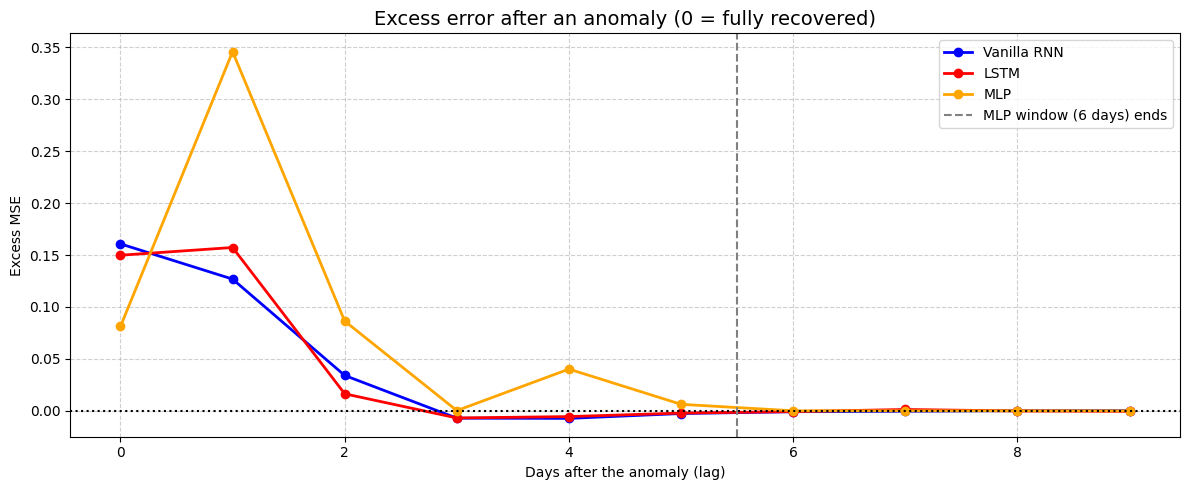

In [41]:
#@title Anomalies: excess error after a spike / drop

set_seed(31)
anomaly_clean = make_dataset(60, 100)
anomaly_observed, anomaly_positions = [], []
for s in anomaly_clean:
    observed, positions = add_anomalies(s, 0.03)
    anomaly_observed.append(observed)
    anomaly_positions.append(positions)

def anomaly_recovery(model, clean_seqs, observed_seqs, positions, max_lag=9, margin=10):
    sums, count = [0.0] * (max_lag + 1), 0
    for clean, observed, pos in zip(clean_seqs, observed_seqs, positions):
        preds_observed = model.predict_sequence(observed)
        preds_clean = model.predict_sequence(clean)
        for s in pos:
            isolated = all(abs(s - p) > margin for p in pos if p != s)
            if isolated and s >= margin and s + max_lag + 1 < len(clean) - 1:
                for lag in range(max_lag + 1):
                    t = s + lag
                    sums[lag] += (preds_observed[t] - clean[t + 1]) ** 2 - (preds_clean[t] - clean[t + 1]) ** 2
                count += 1
    return [v / count for v in sums], count

recovery = {}
for name in ['Vanilla RNN', 'LSTM', 'MLP']:
    recovery[name], n_events = anomaly_recovery(clean_models[name], anomaly_clean, anomaly_observed, anomaly_positions)

n_total = sum(len(p) for p in anomaly_positions)
print(f"{n_total} anomalies injected, {n_events} of them isolated and used for the analysis")
rows = [[name] + [f"{v:+.3f}" for v in recovery[name]] for name in recovery]
print_table(['Excess MSE at lag ->'] + [str(l) for l in range(10)], rows)

fig, ax = plt.subplots(1, 1, figsize=(12, 5))
for name, color in [('Vanilla RNN', 'blue'), ('LSTM', 'red'), ('MLP', 'orange')]:
    ax.plot(range(10), recovery[name], color=color, linewidth=2, marker='o', label=name)
ax.axhline(0, color='black', linestyle=':')
ax.axvline(5.5, color='gray', linestyle='--', label='MLP window (6 days) ends')
ax.set_title('Excess error after an anomaly (0 = fully recovered)', fontsize=14)
ax.set_xlabel('Days after the anomaly (lag)')
ax.set_ylabel('Excess MSE')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

### 15.4 Changing regimes

Here the rules themselves change halfway through each sequence (day 32 of 64). We compare:
* the **RNN trained only on regime A** (the one from section 14), which has never seen regime B;
* three models **trained on sequences that contain the switch**, so in principle they can learn to guess which regime they are in from the recent history (for example, if the last time we saw $0.0 \rightarrow 0.5$ it was followed by $0.0$ and not by $1.0$, we are in regime B);
* an oracle that **knows** the true regime at every day.

We cut the evaluation into three parts: before the switch (days 6 to 31), the six days right after the switch (days 32 to 37), and later (days 38 to 63).

In [42]:
#@title Regime change: data and models

class RegimeOracle:
    # knows the generating rules AND which regime each day belongs to
    def __init__(self, switch_at):
        self.switch_at = switch_at

    def predict_sequence(self, inputs):
        oracle = OracleBaseline()
        preds = [0.5]
        for t in range(1, len(inputs)):
            regime = 'A' if t + 1 < self.switch_at else 'B'
            preds.append(oracle.expected_next(inputs[t - 1], inputs[t], regime))
        return preds

def make_regime_dataset(n, length, switch_at):
    return [generate_regime_sequence(length, [random.choice(states), random.choice(states)], switch_at) for _ in range(n)]

switch_day = 32
set_seed(51)
regime_train = make_regime_dataset(n_train_sequences, sequence_length, switch_day)
regime_val = make_regime_dataset(n_val_sequences, sequence_length, switch_day)
regime_test = make_regime_dataset(30, sequence_length, switch_day)
regime_windows = (make_windows(regime_train, context_length), make_windows(regime_val, context_length),
                  make_windows(regime_test[:n_test_sequences], context_length))

regime_runs = compare_models('Changing regimes', regime_windows)

regime_models = {
    'RNN trained on regime A only': clean_models['Vanilla RNN'],
    'RNN trained with switches': regime_runs['Vanilla RNN']['model'],
    'LSTM trained with switches': regime_runs['LSTM']['model'],
    'MLP trained with switches': regime_runs['MLP']['model'],
    'Markov-2 table (switch data)': Markov2Baseline(regime_train),
    'Oracle that knows the regime': RegimeOracle(switch_day),
}
regime_errors = {name: stepwise_errors(model, regime_test, regime_test) for name, model in regime_models.items()}

rows = []
for name in regime_models:
    e = regime_errors[name]
    rows.append([name, f"{mean_error(e, 5, 31):.4f}", f"{mean_error(e, 31, 37):.4f}", f"{mean_error(e, 37, 62):.4f}"])
print_table(['Test MSE', 'before the switch (day 6-31)', 'right after (day 32-37)', 'later (day 38-63)'], rows)

Test MSE                     | before the switch (day 6-31) | right after (day 32-37) | later (day 38-63)
-----------------------------+------------------------------+-------------------------+------------------
RNN trained on regime A only | 0.0765                       | 0.4720                  | 0.4635           
RNN trained with switches    | 0.1172                       | 0.2312                  | 0.1430           
LSTM trained with switches   | 0.1010                       | 0.2368                  | 0.1215           
MLP trained with switches    | 0.1441                       | 0.2328                  | 0.1685           
Markov-2 table (switch data) | 0.1631                       | 0.2150                  | 0.2116           
Oracle that knows the regime | 0.0687                       | 0.1000                  | 0.0994           


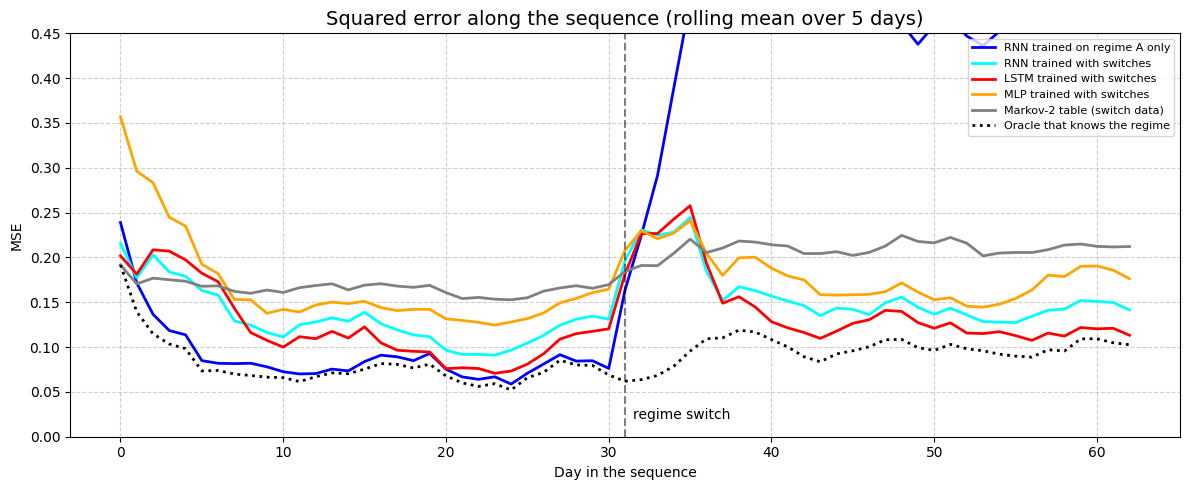

In [43]:
#@title Regime change: error along the sequence

fig, ax = plt.subplots(1, 1, figsize=(12, 5))
colors = ['blue', 'cyan', 'red', 'orange', 'gray', 'black']
for (name, errs), color in zip(regime_errors.items(), colors):
    ax.plot(range(len(errs)), rolling_mean(errs, 5), color=color, linewidth=2,
            linestyle=':' if name.startswith('Oracle') else '-', label=name)
ax.axvline(switch_day - 1, color='black', linestyle='--', alpha=0.5)
ax.text(switch_day - 0.5, 0.02, 'regime switch', fontsize=10)
ax.set_title('Squared error along the sequence (rolling mean over 5 days)', fontsize=14)
ax.set_xlabel('Day in the sequence')
ax.set_ylabel('MSE')
ax.set_ylim(0, 0.45)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### What we see
**Periodic.** All three architectures learn the cycle perfectly (100% accuracy, MSE 0.0001). The Markov-2 table (0.031) and persistence (0.126) do not, which confirms the models use **more than 2 days** of history. But the surprise is how *little* memory it takes: an RNN with only **2** hidden units already gets 100% (MSE 0.0005), and the MLP is as good as the others. The reason is that our cycle has a period of 8 and the MLP's 6-day window is enough to tell where we are in it. To separate the architectures we would need a cycle longer than the window.

**Noise.** The models were trained on clean data.
* Up to $\sigma = 0.05$ nothing changes. After that, all models degrade towards the persistence baseline.
* The clean-trained **RNN is a bit more robust than the MLP in MSE** (0.087 vs 0.098 at $\sigma = 0.1$ and 0.154 vs 0.173 at $\sigma = 0.2$), but in accuracy the MLP is not worse at $\sigma = 0.2$ (59% vs 56%). The LSTM is in between. These are single trained models, so differences of 0.001 to 0.01 are within noise and only the larger gaps are worth noticing.
* The **Markov-2 table is the best of all up to $\sigma = 0.1$ (0.0685)**, because it snaps each price to the nearest state, which removes small noise completely, but it falls apart beyond that, where a wrong snap sends it to the wrong row (0.162 at 0.2). The neural networks degrade more gradually.
* **Training with noise helps when there is noise:** the RNN trained at $\sigma = 0.2$ gets 0.124 at $\sigma = 0.2$ (vs 0.154) and 0.168 at 0.3 (vs 0.213), at no cost on clean data (0.0743 vs 0.0751). The MLP trained with noise is worse on clean data (0.094), probably because it is slower to fit.

**Anomalies.** Right after a spike or a drop the error jumps for all models, and what changes is how long it stays:
* The **RNN and the LSTM recover in about 3 days**: the excess error is 0.16 and 0.13 at lags 0 and 1, 0.03 at lag 2, and then zero (slightly negative, which is just noise).
* The **MLP is hit harder at lag 1 (+0.35)** and has a second smaller bump at lag 4 (+0.04), and returns to exactly zero at lag 6, when the anomaly leaves its 6-day window. Its recovery is bounded by the window, not by what it learned.
* So the RNN's memory is not "longer" than the MLP's window here: the anomaly only affects it for about 3 days. Our guess is that the large input pushes the tanh units into saturation and then the next normal inputs overwrite that state quickly, but we did not test this explanation. There are 76 isolated anomalies behind these curves and one trained model per type.

**Changing regimes.**
* The **RNN trained on regime A only fails after the switch** (MSE 0.47 vs the oracle's 0.10) and does **not** recover: it is still 0.46 later. This is exactly what fixed weights mean: it keeps applying the old rules. It is also the best model before the switch (0.077, near the oracle's 0.069).
* The models **trained with switches adapt partially**: later in the sequence the RNN gets 0.143, the LSTM 0.122 and the MLP 0.169, against the oracle's 0.099. The Markov-2 table cannot do it at all (0.212): two days are not enough to know which regime we are in, so the models that can read a longer history have an advantage. A model that has to infer the regime pays a price before the switch too (0.10 to 0.14 vs 0.077).
* In the first six days after the switch, **every model trained with switches is bad (about 0.23)**: it takes a few observations that contradict the old rules before the hidden state can tell that the regime has changed. The LSTM is the best of the three models in the later period, but each of these is one trained model on 30 test sequences, so the gap between the RNN and the LSTM is suggestive and not proven.

## 16. Hidden State Analysis: What Is the RNN Actually Remembering?

Our first RNN keeps 8 numbers (its hidden state $h_t$) at every day:

$$h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b_h)$$

Until now we only looked at the output. Here we open the box, using the RNN we trained in section 5 (800 epochs), and we visualize:
1. **A heatmap** of all 8 units over a sequence, together with the prices the network saw.
2. **Every unit over time**, one by one.
3. **The same current input after different histories.** If the hidden state is just a copy of the current price, the three hidden vectors will be the same. If the network really uses its memory, they will differ. The two histories that differ only in *older* days (but share the last two days) are the control: they should look similar, because by our rules the older days do not matter.
4. **The average hidden state for each (yesterday, today) pair**, to see if the network organizes its memory by the rules of the environment.

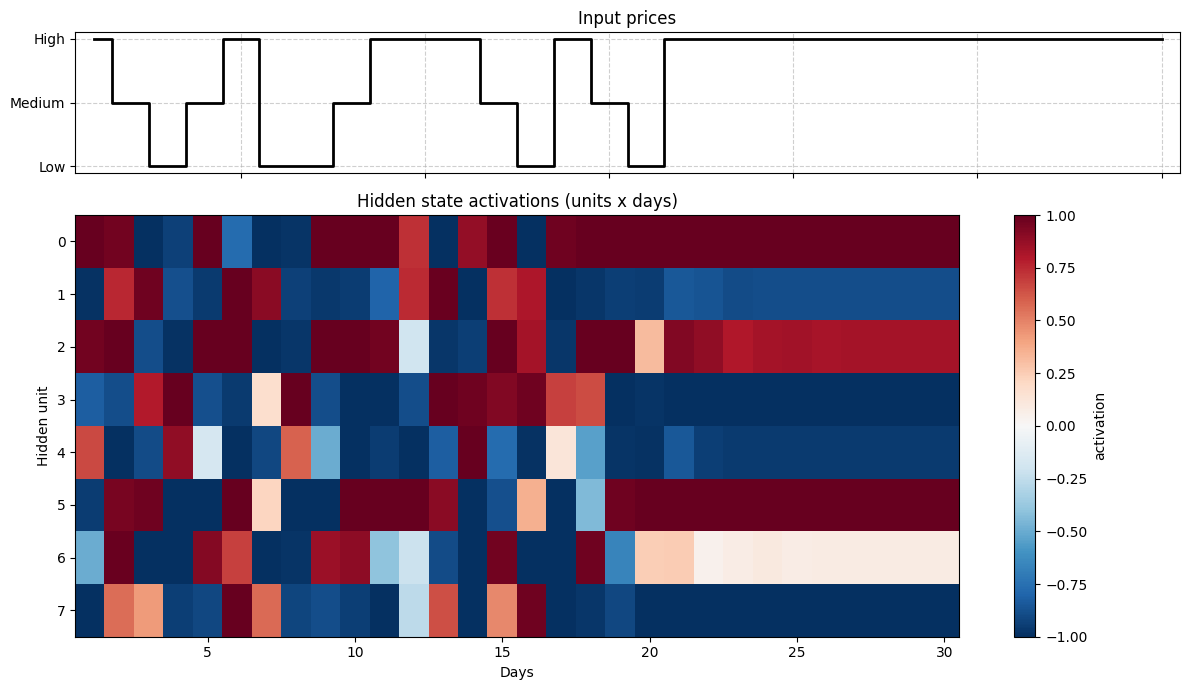

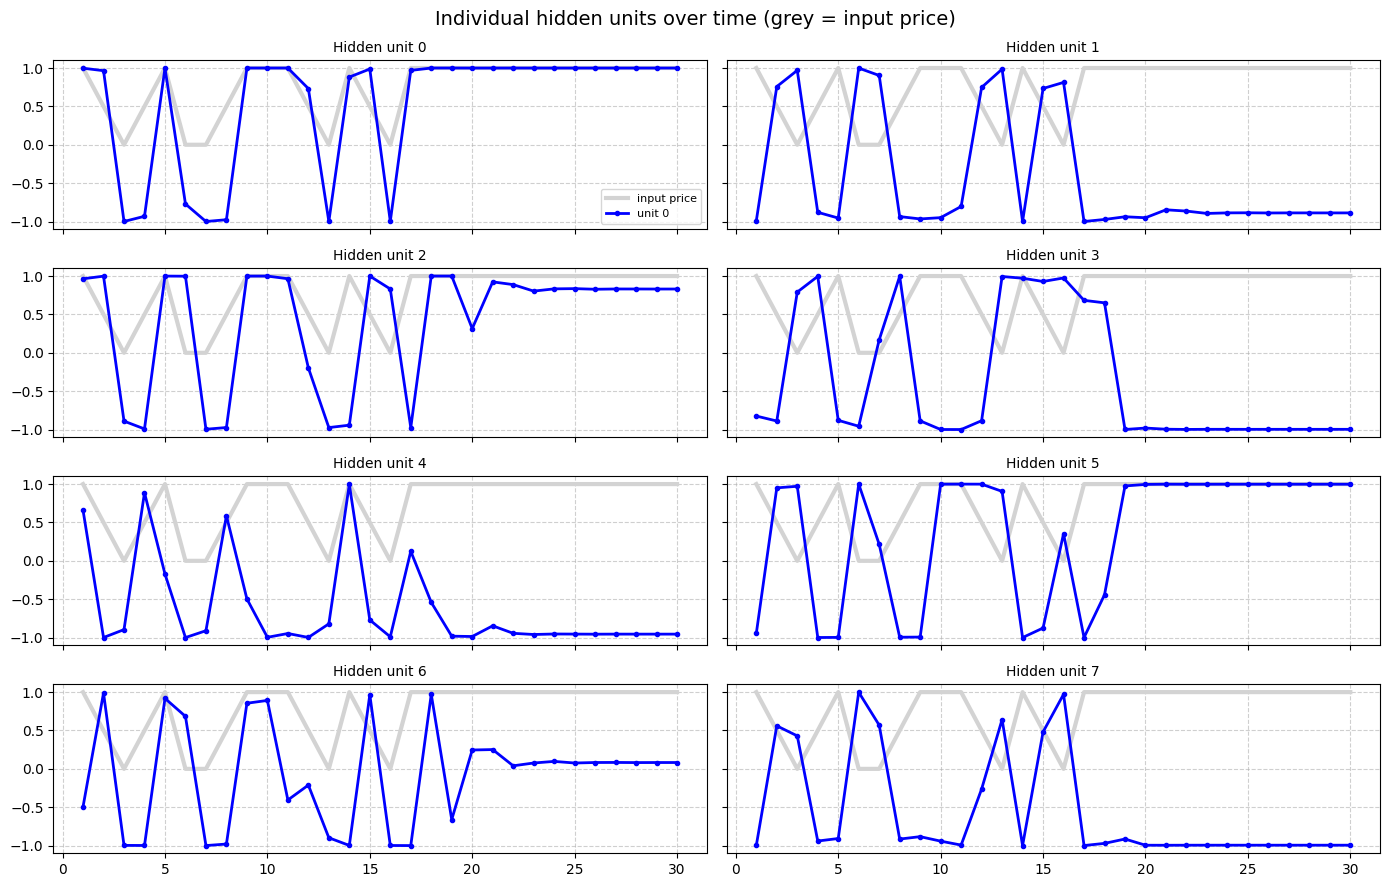

In [44]:
#@title Hidden state heatmap and individual units over a sequence

n_days = 30
sequence = test_sequences[0][:n_days]
_, h, y = rnn.forward(sequence)
hidden_matrix = [[h[t][i][0] for t in range(n_days)] for i in range(hidden_nodes)]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [1, 3]})
axes[0].step(range(1, n_days + 1), sequence, where='mid', color='black', linewidth=2)
axes[0].set_yticks([0.0, 0.5, 1.0])
axes[0].set_yticklabels(['Low', 'Medium', 'High'])
axes[0].set_title('Input prices', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.6)

image = axes[1].imshow(hidden_matrix, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1,
                       extent=[0.5, n_days + 0.5, hidden_nodes - 0.5, -0.5])
axes[1].set_title('Hidden state activations (units x days)', fontsize=12)
axes[1].set_xlabel('Days')
axes[1].set_ylabel('Hidden unit')
fig.colorbar(image, ax=axes[1], label='activation')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 2, figsize=(14, 9), sharex=True, sharey=True)
for i, ax in enumerate(axes.flatten()):
    ax.plot(range(1, n_days + 1), sequence, color='lightgray', linewidth=3, label='input price')
    ax.plot(range(1, n_days + 1), hidden_matrix[i], color='blue', linewidth=2, marker='o', markersize=3, label=f'unit {i}')
    ax.set_title(f'Hidden unit {i}', fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.6)
axes[0][0].legend(fontsize=8)
fig.suptitle('Individual hidden units over time (grey = input price)', fontsize=14)
plt.tight_layout()
plt.show()

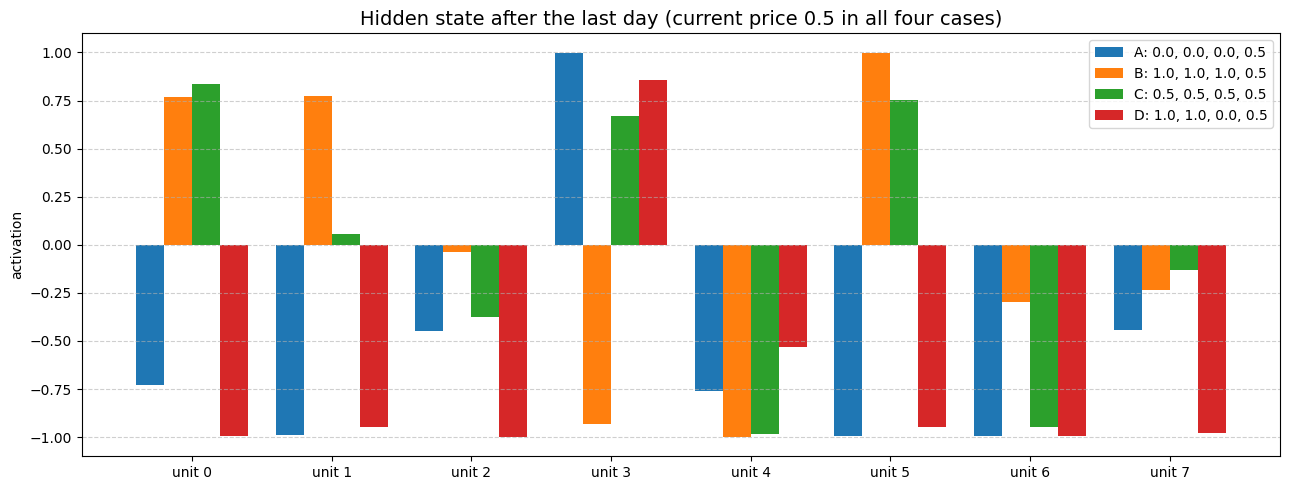

prediction for tomorrow:
  A: 0.0, 0.0, 0.0, 0.5   (surge, next should be 1.0) -> 0.98
  B: 1.0, 1.0, 1.0, 0.5   (crash, next should be 0.0) -> 0.01
  C: 0.5, 0.5, 0.5, 0.5   (no rule, random) -> 0.10
  D: 1.0, 1.0, 0.0, 0.5   (surge, but older days differ from A) -> 0.99

distance between hidden states A and B (different yesterday): 3.712
distance between hidden states A and C (different yesterday): 2.616
distance between hidden states A and D (same last two days, different older days): 0.858


In [45]:
#@title The same current input (0.5) after different histories

histories = {
    'A: 0.0, 0.0, 0.0, 0.5   (surge, next should be 1.0)': [0.0, 0.0, 0.0, 0.5],
    'B: 1.0, 1.0, 1.0, 0.5   (crash, next should be 0.0)': [1.0, 1.0, 1.0, 0.5],
    'C: 0.5, 0.5, 0.5, 0.5   (no rule, random)': [0.5, 0.5, 0.5, 0.5],
    'D: 1.0, 1.0, 0.0, 0.5   (surge, but older days differ from A)': [1.0, 1.0, 0.0, 0.5],
}

final_states, outputs = {}, {}
for name, hist in histories.items():
    _, h_hist, y_hist = rnn.forward(hist)
    final_states[name] = [h_hist[len(hist) - 1][i][0] for i in range(hidden_nodes)]
    outputs[name] = y_hist[len(hist) - 1][0][0]

fig, ax = plt.subplots(1, 1, figsize=(13, 5))
width = 0.2
for k, (name, vec) in enumerate(final_states.items()):
    ax.bar([i + k * width for i in range(hidden_nodes)], vec, width=width, label=name.split('(')[0].strip())
ax.set_xticks([i + 1.5 * width for i in range(hidden_nodes)])
ax.set_xticklabels([f'unit {i}' for i in range(hidden_nodes)])
ax.set_title('Hidden state after the last day (current price 0.5 in all four cases)', fontsize=14)
ax.set_ylabel('activation')
ax.grid(True, linestyle='--', alpha=0.6, axis='y')
ax.legend()
plt.tight_layout()
plt.show()

def distance(a, b):
    return math.sqrt(sum((p - q) ** 2 for p, q in zip(a, b)))

names = list(histories)
print("prediction for tomorrow:")
for name in names:
    print(f"  {name} -> {outputs[name]:.2f}")
print()
print(f"distance between hidden states A and B (different yesterday): {distance(final_states[names[0]], final_states[names[1]]):.3f}")
print(f"distance between hidden states A and C (different yesterday): {distance(final_states[names[0]], final_states[names[2]]):.3f}")
print(f"distance between hidden states A and D (same last two days, different older days): {distance(final_states[names[0]], final_states[names[3]]):.3f}")

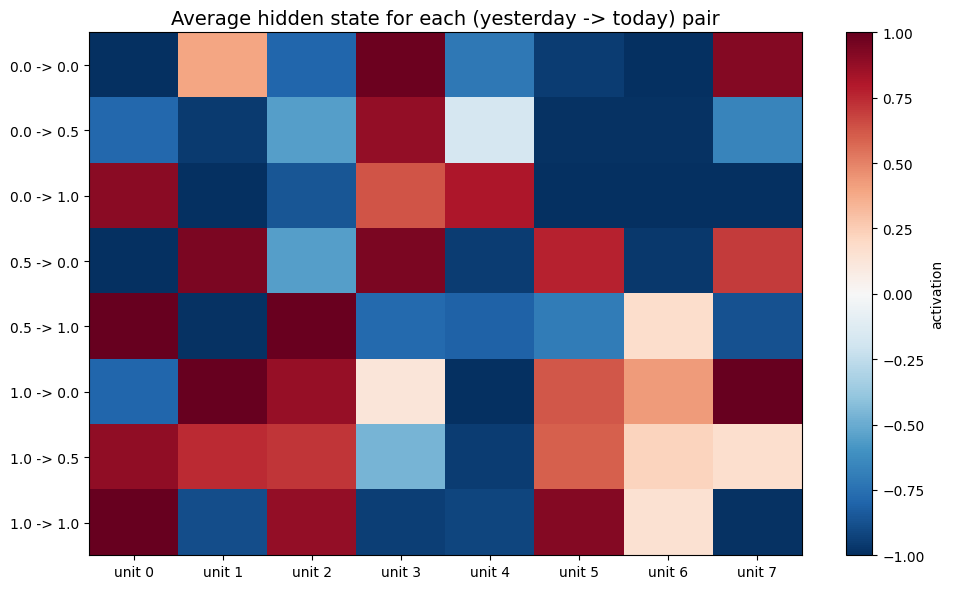

In [46]:
#@title Average hidden state for each (yesterday, today) pair

pair_states = {}
for inputs, targets in test_windows:
    _, h_window, _ = rnn.forward(inputs)
    last = [h_window[len(inputs) - 1][i][0] for i in range(hidden_nodes)]
    pair_states.setdefault((inputs[-2], inputs[-1]), []).append(last)

pairs = sorted(pair_states)
pair_matrix = [[sum(v[i] for v in pair_states[p]) / len(pair_states[p]) for i in range(hidden_nodes)] for p in pairs]

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
image = ax.imshow(pair_matrix, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_yticks(range(len(pairs)))
ax.set_yticklabels([f'{p[0]} -> {p[1]}' for p in pairs])
ax.set_xticks(range(hidden_nodes))
ax.set_xticklabels([f'unit {i}' for i in range(hidden_nodes)])
ax.set_title('Average hidden state for each (yesterday -> today) pair', fontsize=14)
fig.colorbar(image, ax=ax, label='activation')
plt.tight_layout()
plt.show()

### What we see
* **The heatmap:** the units are mostly saturated, close to +1 or -1, so the hidden state is nearly a binary code. It changes with every new price, and when the price stays High for many days (day 20 on) it settles into a **fixed pattern** that does not change any more. That fixed pattern is the network's representation of "the ceiling".
* **The same current input after different histories:** the hidden state is **not** just a copy of today's price. Histories A and B both end with a 0.5, but the hidden states are very different (distance 3.7) and the network predicts 0.98 and 0.01, which are the surge and the crash. So the network is using its memory of yesterday. For the control, history D has the same last two days as A but different older days, and its hidden state is much closer to A (distance 0.86), with the same prediction (0.99). So the representation is mostly about the last two days, as the rules say, with a small trace of older days.
* **One failure:** for history C (0.5, 0.5, 0.5, 0.5) the network predicts 0.10, while the average outcome of this pair in the environment is 0.5 (a random transition). This pair is probably very rare in the single sequence it was trained on, but we did not check that.
* **The pair averages:** each of the 9 (yesterday $\rightarrow$ today) pairs gets its own pattern of unit activations. In particular, the two rules with the same current price (0.0 $\rightarrow$ 0.5 and 1.0 $\rightarrow$ 0.5) are almost opposite in units 0, 1 and 2. The network organized its memory around the pairs that matter for the rules.

## 17. Results

Everything we ran above added one line to the `results` list, so here is the whole experiment table in one place. All the numbers are on the **test** sequences (validation numbers are only used to choose things, like the optimizer). Remember that the noise floor of the stock environment (the oracle) is the lowest possible MSE, so we always read a model's MSE *relative to the oracle's*, not relative to zero.

In [47]:
#@title The full experiment table

oracle_test = evaluate(OracleBaseline(), test_windows)
print(f"reference: oracle on the stock environment | Test MSE {oracle_test['mse']:.4f} | MAE {oracle_test['mae']:.4f} | accuracy {oracle_test['acc'] * 100:.1f}%")
print()
print_table(['Experiment', 'Model', 'Params', 'Train MSE', 'Val MSE', 'Test MSE', 'Test MAE', 'Test acc'], results)

reference: oracle on the stock environment | Test MSE 0.0673 | MAE 0.1767 | accuracy 71.0%

Experiment                    | Model                                    | Params | Train MSE | Val MSE | Test MSE | Test MAE | Test acc
------------------------------+------------------------------------------+--------+-----------+---------+----------+----------+---------
RNN vs MLP (SGD)              | Vanilla RNN (100 epochs)                 | 89     | 0.0704    | 0.0570  | 0.0711   | 0.1985   | 71.3%   
RNN vs MLP (SGD)              | Vanilla RNN, last-step signal only (100) | 89     | 0.1057    | 0.0747  | 0.0960   | 0.2476   | 64.8%   
RNN vs MLP (SGD)              | MLP (100 epochs)                         | 89     | 0.1338    | 0.0992  | 0.1180   | 0.3010   | 47.1%   
RNN vs MLP (SGD)              | MLP (300 epochs)                         | 89     | 0.0956    | 0.0738  | 0.0878   | 0.2457   | 62.2%   
Hidden size (Adam)            | Vanilla RNN, 2 hidden                    | 11     | 0.

## 18. Limitations: What Vanilla RNNs Struggle With (and What Our Experiments Could Not Show)

**What the experiments show about the Vanilla RNN**
* **Vanishing gradients are real and fast.** With the initialization we used, only 0.04% of the gradient reaches 4 days back, and nothing at all reaches 50 days back. Gradient clipping does not help with this, and a better initialization (orthogonal) helps a lot.
* **Fixed weights do not adapt.** After the regime switch, the RNN trained on one regime keeps using its old rules. Adapting needs either training on data that contains the changes, or a mechanism that updates the weights online.
* **It is sensitive to inputs outside what it saw in training** (anomalies and noise), although in our experiments it recovered from shocks within about 3 days.
* **It is slow.** The recurrent steps cannot be run in parallel across time, and in our pure Python version the cost grows with the square of the hidden size.

**What our experiments could not show (limits of this work)**
* **Our environment needs only 2 days of memory**, so it never really punishes the vanishing gradient. That is why the MLP matched the RNN, why the LSTM did not beat the RNN, and why a 2-unit RNN solved the periodic task. We did *not* demonstrate a task where the Vanilla RNN fails and the LSTM works.
* **Small data and few seeds.** 8 training sequences, 10 test sequences, and 1 to 3 seeds depending on the experiment. Differences of about 0.002 in MSE are noise. We tried to only draw conclusions from larger gaps.
* **Training budget is part of every comparison.** The RNN vs MLP result changes completely depending on how long the MLP trains.
* **We tested one clipping method** (element-wise) and not norm clipping, and the exploding-gradient training experiment is a single short run.
* **Everything is synthetic.** The noise floor of our environment is known exactly, which is great for evaluation, but real data is not like this.

## 19. Conclusion

We started with a working Vanilla RNN and a theory section, and we turned each claim of the theory into a measurement.

| Claim from the theory | What we measured |
|---|---|
| "Feedforward networks cannot handle sequences" | Only partly true. An MLP with a window of 6 solved a task that needs 2 days, but it trained more slowly per epoch (one signal per window instead of six). A fixed window is a hard limit only for longer dependencies. |
| "RNNs support sequences of any length" | True for stability: no loss of quality from 7 to 100 days. But it says nothing about being able to *use* old information. |
| "Gradients vanish or explode" | Measured. The factor per step was 0.15 for our initialization, above 1 for large ones, and about 0.97 for an orthogonal one. |
| "We use clipping to prevent explosions" | Clipping never touches vanishing gradients, and in our one exploding run it did not help. |
| "LSTMs fix the long-term dependency problem" | Their gradient flow is much better at the start, but the decay is not gone, and on our environment there was nothing to fix. |

**Findings that we did not expect:** the first RNN was already almost as good as the oracle; the MLP's weakness in our first table was mostly a training-budget effect; the optimizers differ mostly in how sensitive they are to the learning rate and not in the final loss; and clipping did worse than no clipping in the exploding run.

**Possible improvements / future work**
1. A task that really requires long memory (for example, a recall task over 20+ days, or a periodic cycle longer than the window), with several seeds, to test the vanishing gradient and the LSTM where they should matter.
2. Norm-based gradient clipping, and a comparison with element-wise clipping.
3. Mini-batches and a learning rate schedule (we used one window per update).
4. A GRU, and a multi-layer RNN.
5. A longer training for the 32-unit model, to check if its higher loss is just under-training.